# Segundo parcial: aprendizaje no supervisado




## 1. Importar las librerías


In [1]:
import os
import gc
from PIL import Image
import matplotlib.pyplot as plt

%matplotlib inline


## 2. Localizar las carpetas y comprobar el dataset tratado



In [2]:
carpeta_datos = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\dataset quirpinchaca 03"
carpeta_tratada = os.path.join(
    os.path.dirname(carpeta_datos), "dataset ya tratado"
)
usar_dataset_tratado = os.path.isdir(carpeta_tratada)

archivos_originales = sorted(os.listdir(carpeta_datos))
total_imagenes = len(archivos_originales)

if usar_dataset_tratado:
    imagenes = []
    imagenes_corregidas = {}
    plt.close("all")
    gc.collect()
    print("Dataset ya tratado encontrado. Se omitira el procesamiento completo.")
else:
    print("La carpeta tratada no existe. Se prepararan las fotos originales.")

print("Fotos originales disponibles:", total_imagenes)
print("Carpeta tratada:", carpeta_tratada)


Dataset ya tratado encontrado. Se omitira el procesamiento completo.
Fotos originales disponibles: 177
Carpeta tratada: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\dataset ya tratado


## 3. Preparar una vista previa de la primera imagen




In [3]:
nombre_imagen = archivos_originales[0]
ruta_imagen = os.path.join(carpeta_datos, nombre_imagen)

with Image.open(ruta_imagen) as foto:
    dimensiones_originales = foto.size
    foto.thumbnail((800, 600))
    imagen = foto.copy()

print("Imagen:", nombre_imagen)
print("Dimensiones originales:", dimensiones_originales)


Imagen: Copia de Copia de IMG_20260914_100122.jpg
Dimensiones originales: (4096, 3072)


## 4. Mostrar la imagen


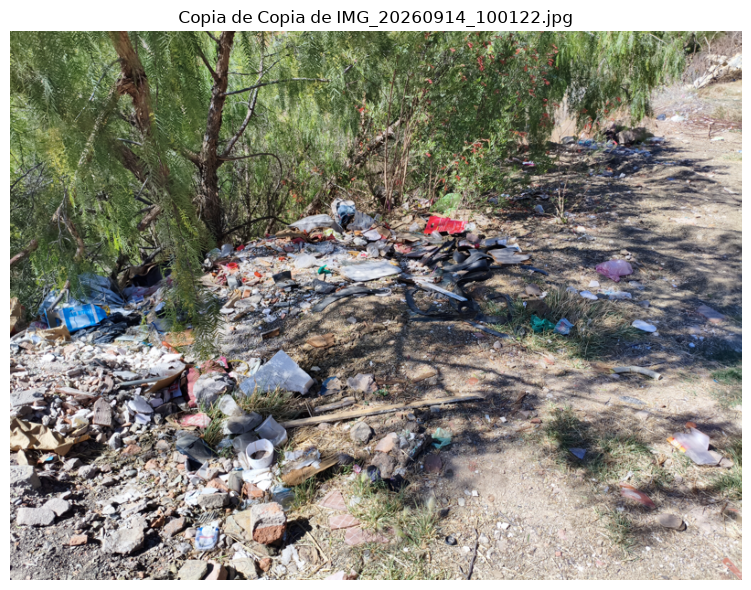

In [4]:
plt.figure(figsize=(8, 6))
plt.imshow(imagen)
plt.title(nombre_imagen)
plt.axis("off")
plt.tight_layout()
plt.show()
plt.close("all")


## 5. Consultar las dimensiones para las comprobaciones




In [5]:
from PIL import Image

archivos_horizontales = []
archivos_verticales = []
archivos_otro_tamano = []

for archivo in archivos_originales:
    ruta = os.path.join(carpeta_datos, archivo)

    with Image.open(ruta) as foto:
        ancho, alto = foto.size

    if ancho == 4096 and alto == 3072:
        archivos_horizontales.append(archivo)
    elif alto > ancho:
        archivos_verticales.append(archivo)
    else:
        archivos_otro_tamano.append(archivo)

print("Imagenes verticales:", len(archivos_verticales))
print("Horizontales de 4096 x 3072:", len(archivos_horizontales))
print("Otras dimensiones (no verticales):", len(archivos_otro_tamano))
print("Total revisado:", len(archivos_originales))


Imagenes verticales: 15
Horizontales de 4096 x 3072: 162
Otras dimensiones (no verticales): 0
Total revisado: 177


## 6. Ver las imágenes verticales con su índice




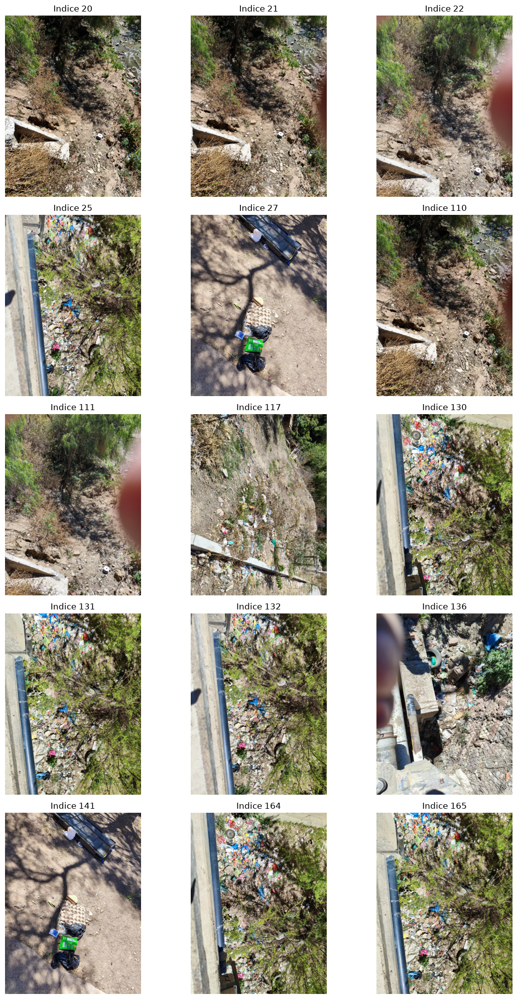

Indices de las imagenes verticales: [20, 21, 22, 25, 27, 110, 111, 117, 130, 131, 132, 136, 141, 164, 165]
Vista de comprobacion. Se mantienen los giros guardados en la seccion 7.


In [ ]:
indices_verticales = [
    archivos_originales.index(archivo) for archivo in archivos_verticales
]


filas = max(1, (len(indices_verticales) + 2) // 3)
fig, ejes = plt.subplots(filas, 3, figsize=(12, 4 * filas), squeeze=False)


for eje in ejes.flat:
    eje.axis("off")

for eje, indice in zip(ejes.flat, indices_verticales):
    archivo = archivos_originales[indice]
    ruta = os.path.join(carpeta_datos, archivo)

    with Image.open(ruta) as foto:
        foto.thumbnail((480, 640))
        eje.imshow(foto)

    eje.set_title(f"Indice {indice}")
    eje.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)

print("Indices de las imagenes verticales:", indices_verticales)
if not usar_dataset_tratado:
    print("\nCopia este diccionario a la siguiente celda:\n")
    print("giros_verticales = {")
    for indice in indices_verticales:
        print(f"    {indice}: -1,")
    print("}")
else:
    print("Vista de comprobacion. Se mantienen los giros guardados en la seccion 7.")


## 7. Giros manuales guardados




In [7]:
giros_verticales = {
    20: 0,
    21: 0,
    22: 0,
    25: 0,
    27: 0,
    110: 0,
    111: 0,
    117: 0,
    130: 0,
    131: 0,
    132: 0,
    136: 0,
    141: 0,
    164: 0,
    165: 0,
}

## 8. Comprobar los giros de las imágenes verticales




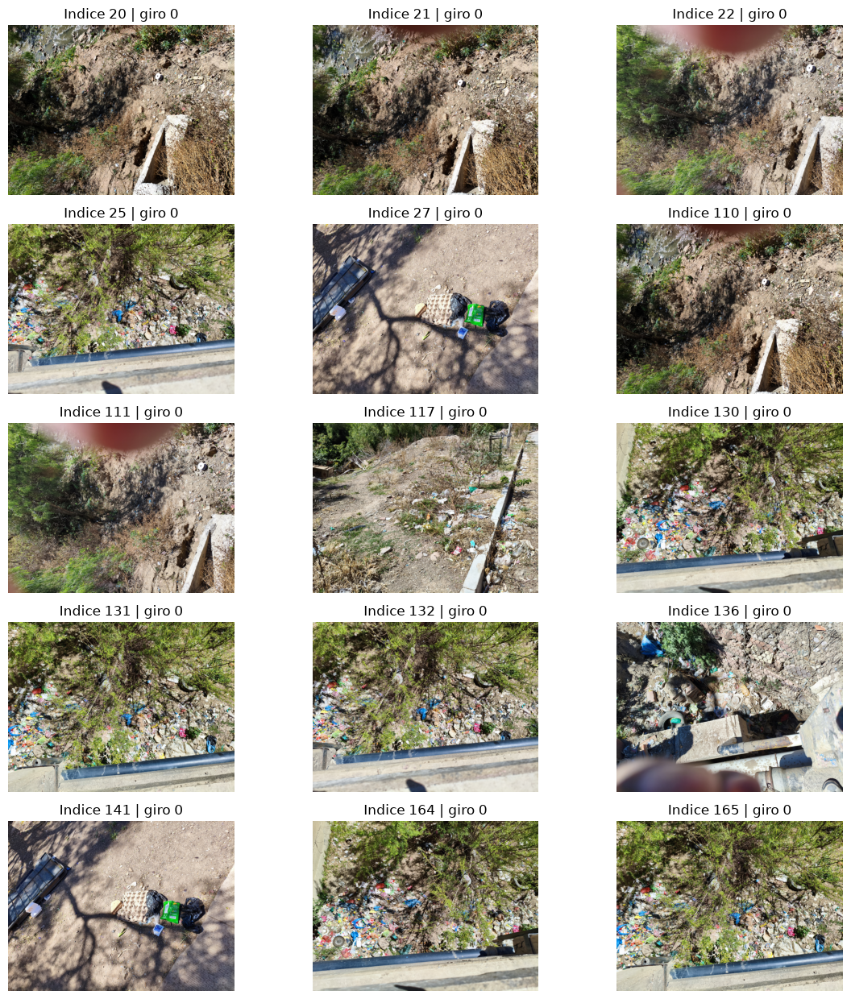

Comprobacion con miniaturas. El dataset tratado ya esta guardado.


In [8]:
for indice in indices_verticales:
    if giros_verticales.get(indice) not in (0, 1):
        raise ValueError(f"Revisa el indice {indice}: debes poner 0 o 1.")

imagenes_corregidas = {}
filas = max(1, (len(indices_verticales) + 2) // 3)
fig, ejes = plt.subplots(filas, 3, figsize=(12, 2.5 * filas), squeeze=False)

for eje in ejes.flat:
    eje.axis("off")

for eje, indice in zip(ejes.flat, indices_verticales):
    ruta = os.path.join(carpeta_datos, archivos_originales[indice])

    with Image.open(ruta) as foto:
        if usar_dataset_tratado:
            foto.thumbnail((640, 640))

        if giros_verticales[indice] == 0:
            foto_girada = foto.rotate(90, expand=True)
        else:
            foto_girada = foto.rotate(-90, expand=True)

    if not usar_dataset_tratado:
        imagenes_corregidas[indice] = foto_girada

    vista = foto_girada.copy()
    vista.thumbnail((640, 480))
    eje.imshow(vista)
    eje.set_title(f"Indice {indice} | giro {giros_verticales[indice]}")

plt.tight_layout()
plt.show()
plt.close(fig)

if usar_dataset_tratado:
    print("Comprobacion con miniaturas. El dataset tratado ya esta guardado.")
else:
    print("Imagenes corregidas en memoria:", len(imagenes_corregidas))


## 9. Cargar las fotos grandes solo cuando haga falta generar el dataset




In [9]:
imagenes = []

if usar_dataset_tratado:
    print("Carga de fotos grandes omitida: se usara el dataset ya tratado.")
else:
    for indice, archivo in enumerate(archivos_originales):
        if indice in imagenes_corregidas:
            foto_dataset = imagenes_corregidas[indice]
        else:
            ruta = os.path.join(carpeta_datos, archivo)
            with Image.open(ruta) as foto_original:
                foto_dataset = foto_original.copy()

        imagenes.append(foto_dataset)

    print("Total de imagenes grandes en memoria:", len(imagenes))
    print("Corregidas reutilizadas:", len(imagenes_corregidas))


Carga de fotos grandes omitida: se usara el dataset ya tratado.


## 10. Comprobar el recorte del 60% inferior




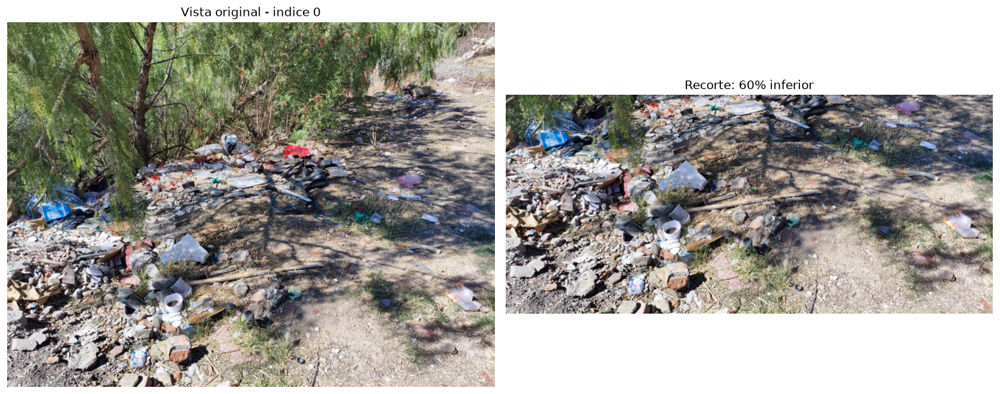

In [10]:
indice_prueba = 0
porcentaje_inferior = 0.60

ruta_prueba = os.path.join(carpeta_datos, archivos_originales[indice_prueba])
with Image.open(ruta_prueba) as foto:
    foto.thumbnail((1000, 1000))
    imagen_original = foto.copy()

if indice_prueba in giros_verticales:
    if giros_verticales[indice_prueba] == 0:
        imagen_original = imagen_original.rotate(90, expand=True)
    elif giros_verticales[indice_prueba] == 1:
        imagen_original = imagen_original.rotate(-90, expand=True)

ancho, alto = imagen_original.size
alto_conservar = int(alto * porcentaje_inferior)
inicio_corte = alto - alto_conservar
imagen_recortada = imagen_original.crop((0, inicio_corte, ancho, alto))

fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
ejes[0].imshow(imagen_original)
ejes[0].set_title(f"Vista original - indice {indice_prueba}")
ejes[1].imshow(imagen_recortada)
ejes[1].set_title(f"Recorte: {int(porcentaje_inferior * 100)}% inferior")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)


## 11. Configurar los recortes de 128 × 128




In [11]:
porcentaje_inferior = 0.60
tamano_recorte = 128
columnas_recortes = 40
filas_recortes = 25
recortes_por_foto = columnas_recortes * filas_recortes

print("Carpeta del dataset:", carpeta_tratada)
if os.path.isdir(carpeta_tratada):
    print("La carpeta ya existe. Se omitira la generacion de recortes.")
else:
    print("Fotos originales:", len(archivos_originales))
    print("Recortes por foto:", recortes_por_foto)
    print("Total esperado:", len(archivos_originales) * recortes_por_foto)


Carpeta del dataset: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\dataset ya tratado
La carpeta ya existe. Se omitira la generacion de recortes.


## 12. Generar los recortes únicamente si falta la carpeta tratada




In [ ]:
usar_dataset_tratado = os.path.isdir(carpeta_tratada)

if usar_dataset_tratado:
    print("Generacion omitida: ya existe el dataset tratado.")
else:
    os.makedirs(carpeta_tratada, exist_ok=True)
    total_guardadas = 0
    
    for indice, foto_original in enumerate(imagenes):
       
        ancho, alto = foto_original.size
        alto_conservar = int(alto * porcentaje_inferior)
        inicio_corte = alto - alto_conservar
        foto_suelo = foto_original.crop((0, inicio_corte, ancho, alto))
        ancho_suelo, alto_suelo = foto_suelo.size
    
        if ancho_suelo < tamano_recorte or alto_suelo < tamano_recorte:
            raise ValueError(f"La foto {indice} es demasiado pequena para recortes de 128 x 128.")
    
        
        nombre_origen = os.path.splitext(archivos_originales[indice])[0]
        carpeta_foto = os.path.join(carpeta_tratada, nombre_origen)
        os.makedirs(carpeta_foto, exist_ok=True)
        numero_recorte = 0
    
        for fila in range(filas_recortes):
            y = fila * (alto_suelo - tamano_recorte) // (filas_recortes - 1)
    
            for columna in range(columnas_recortes):
                x = columna * (ancho_suelo - tamano_recorte) // (columnas_recortes - 1)
                recorte = foto_suelo.crop((
                    x, y, x + tamano_recorte, y + tamano_recorte
                ))
    
                nombre_recorte = f"recorte_{numero_recorte:04d}.png"
                ruta_recorte = os.path.join(carpeta_foto, nombre_recorte)
                recorte.save(ruta_recorte)
    
                numero_recorte += 1
                total_guardadas += 1
    
        print(f"Foto {indice + 1}/{len(imagenes)}: {numero_recorte} recortes guardados")
    
    print("\nTotal de recortes guardados:", total_guardadas)
    print("Dataset guardado en:", carpeta_tratada)
    usar_dataset_tratado = True


Generacion omitida: ya existe el dataset tratado.


## 13. Usar el dataset guardado y liberar las fotos grandes




In [ ]:

imagenes = []
imagenes_corregidas = {}
foto_dataset = None
foto_original = None
foto_suelo = None
foto_girada = None
plt.close("all")
gc.collect()

if not os.path.isdir(carpeta_tratada):
    raise ValueError("Primero genera el dataset en la seccion 12.")

archivos_tratados = []
origenes_tratados = []

for origen in sorted(os.listdir(carpeta_tratada)):
    carpeta_origen = os.path.join(carpeta_tratada, origen)
    if os.path.isdir(carpeta_origen):
        for archivo in sorted(os.listdir(carpeta_origen)):
            if archivo.lower().endswith(".png"):
                archivos_tratados.append(os.path.join(carpeta_origen, archivo))
                origenes_tratados.append(origen)

total_imagenes = len(archivos_tratados)
if total_imagenes == 0:
    raise ValueError("La carpeta tratada existe, pero no contiene recortes PNG.")

print("Dataset activo:", carpeta_tratada)
print("Recortes disponibles:", total_imagenes)
print("Fotos de origen:", len(set(origenes_tratados)))
print("Las imagenes se abriran desde esta carpeta cuando se necesiten.")


Dataset activo: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\dataset ya tratado
Recortes disponibles: 177000
Fotos de origen: 177
Las imagenes se abriran desde esta carpeta cuando se necesiten.


## 14. Ver una muestra del dataset tratado




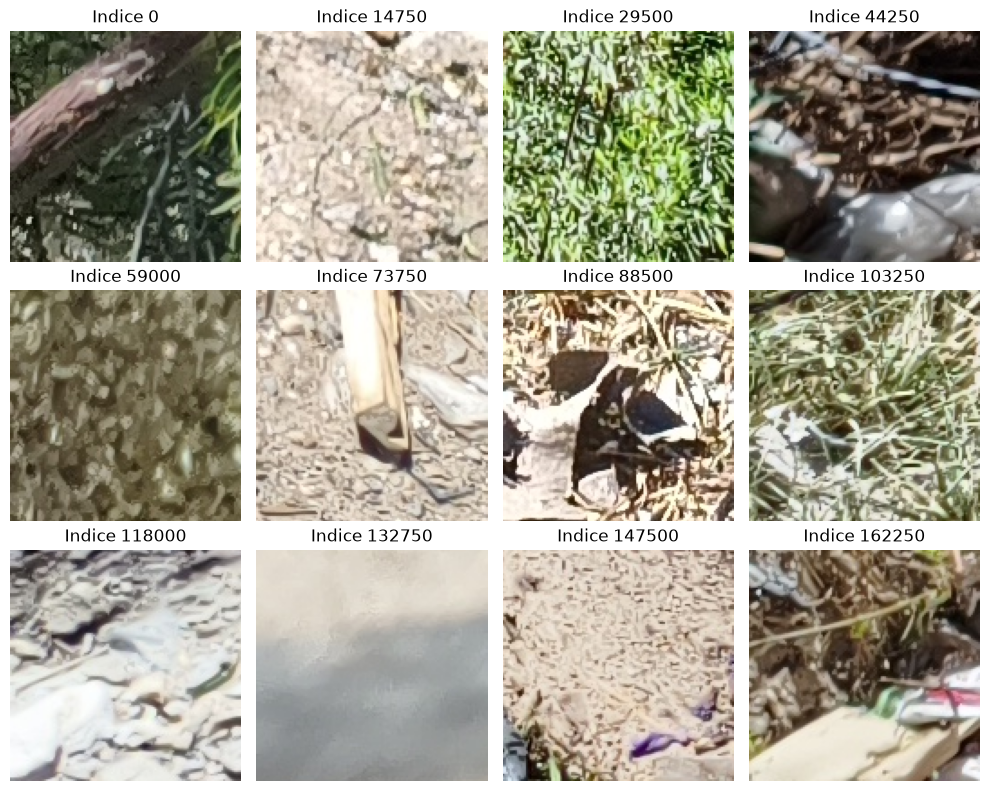

In [14]:
paso = max(1, len(archivos_tratados) // 12)
indices_muestra = list(range(0, len(archivos_tratados), paso))[:12]

fig, ejes = plt.subplots(3, 4, figsize=(10, 8))
for eje in ejes.flat:
    eje.axis("off")

for eje, indice in zip(ejes.flat, indices_muestra):
    with Image.open(archivos_tratados[indice]) as foto:
        eje.imshow(foto)
    eje.set_title(f"Indice {indice}")

plt.tight_layout()
plt.show()
plt.close(fig)


## 15. Recuperar K-Means de 50 y las mismas 45.000 imágenes




In [ ]:
import os
import json
import hashlib
import gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

%matplotlib inline

carpeta_proyecto = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado"
carpeta_tratada = os.path.join(carpeta_proyecto, "dataset ya tratado")
carpeta_resultados = os.path.join(carpeta_proyecto, "resultados eleccion k")
ruta_modelo = os.path.join(carpeta_resultados, "modelos", "kmeans_050.npz")

with open(os.path.join(carpeta_proyecto, "division_fotos.json"), encoding="utf-8") as archivo:
    division = json.load(archivo)
with open(os.path.join(carpeta_resultados, "muestra_entrenamiento.json"), encoding="utf-8") as archivo:
    muestra_relativa = json.load(archivo)
with open(os.path.join(carpeta_resultados, "configuracion_modelos.json"), encoding="utf-8") as archivo:
    configuracion_kmeans = json.load(archivo)

huella_muestra = hashlib.sha256("\n".join(muestra_relativa).encode("utf-8")).hexdigest()
if len(muestra_relativa) != 45000 or huella_muestra != configuracion_kmeans["huella_muestra"]:
    raise ValueError("La muestra no coincide con las 45.000 imagenes del experimento guardado.")

fotos_entrenamiento = set(division["entrenamiento"])
fotos_prueba = set(division["prueba"])
origenes_muestra = {nombre.split("/")[0] for nombre in muestra_relativa}
if fotos_entrenamiento & fotos_prueba or not origenes_muestra.issubset(fotos_entrenamiento):
    raise ValueError("Revisa la division: las fotos de entrenamiento y prueba deben estar separadas.")

archivos_entrenamiento = [os.path.join(carpeta_tratada, nombre) for nombre in muestra_relativa]
with np.load(ruta_modelo, allow_pickle=False) as datos_modelo:
    centroides = datos_modelo["centroides"]
    grupos_kmeans = datos_modelo["etiquetas"]

k = 50
if centroides.shape != (k, 49152) or grupos_kmeans.shape != (45000,):
    raise ValueError("El modelo guardado no corresponde a K=50 con 45.000 imagenes RGB de 128 x 128.")
if np.any(grupos_kmeans < 0) or np.any(grupos_kmeans >= k):
    raise ValueError("El modelo contiene identificadores de grupos inesperados.")
conteos_grupos = np.bincount(grupos_kmeans, minlength=k)
if np.any(conteos_grupos == 0):
    raise ValueError("Hay un grupo vacio; no se puede elegir una imagen de ese grupo.")


with open(ruta_modelo, "rb") as archivo:
    huella_modelo = hashlib.sha256(archivo.read()).hexdigest()

print("K-Means recuperado, sin volver a entrenar. Grupos:", k)
print("Recortes de entrenamiento:", len(archivos_entrenamiento))
print("Fotos de origen en la muestra:", len(origenes_muestra))
print("Fotos originales reservadas para prueba:", len(fotos_prueba))
print("Solo se cargaron las rutas, los centroides y los grupos; no una matriz X grande.")


K-Means recuperado, sin volver a entrenar. Grupos: 50
Recortes de entrenamiento: 45000
Fotos de origen en la muestra: 157
Fotos originales reservadas para prueba: 20
Solo se cargaron las rutas, los centroides y los grupos; no una matriz X grande.


## 16. Seleccionar una imagen representativa por grupo



In [2]:
ruta_representantes = os.path.join(carpeta_resultados, "representantes_k_050.npz")
usar_representantes_guardados = False

if os.path.isfile(ruta_representantes):
    with np.load(ruta_representantes, allow_pickle=False) as datos_representantes:
        if (str(datos_representantes["huella_muestra"]) == huella_muestra
                and str(datos_representantes["huella_modelo"]) == huella_modelo):
            indices_representantes = datos_representantes["indices_representantes"]
            distancias_al_centro = datos_representantes["distancias_al_centro"]
            usar_representantes_guardados = True
    if usar_representantes_guardados:
        print("Representantes y distancias recuperados. No se vuelven a recorrer las imagenes.")

if not usar_representantes_guardados:
    distancias_al_centro = np.empty(len(archivos_entrenamiento), dtype=np.float32)

    for indice, ruta in enumerate(archivos_entrenamiento):
        with Image.open(ruta) as foto:
            if foto.size != (128, 128):
                raise ValueError(f"El recorte no mide 128 x 128: {ruta}")
            vector = np.asarray(foto.convert("RGB"), dtype=np.float32).reshape(-1) / 255.0

        grupo = int(grupos_kmeans[indice])
        distancias_al_centro[indice] = np.linalg.norm(vector - centroides[grupo])
        if (indice + 1) % 1000 == 0:
            print(f"Revisadas {indice + 1}/{len(archivos_entrenamiento)} imagenes", flush=True)

    indices_representantes = np.empty(k, dtype=np.int32)
    for grupo in range(k):
        miembros = np.flatnonzero(grupos_kmeans == grupo)
        indices_representantes[grupo] = miembros[np.argmin(distancias_al_centro[miembros])]

    ruta_temporal = ruta_representantes + ".tmp.npz"
    np.savez_compressed(
        ruta_temporal, indices_representantes=indices_representantes,
        distancias_al_centro=distancias_al_centro,
        huella_muestra=huella_muestra, huella_modelo=huella_modelo
    )
    os.replace(ruta_temporal, ruta_representantes)
    gc.collect()

if indices_representantes.shape != (k,) or distancias_al_centro.shape != (45000,):
    raise ValueError("El archivo de representantes no tiene el tamano esperado.")
if not np.array_equal(grupos_kmeans[indices_representantes], np.arange(k)):
    raise ValueError("Los representantes no corresponden a sus grupos guardados.")

representantes = []
for grupo, indice in enumerate(indices_representantes):
    representantes.append({
        "grupo": grupo,
        "indice_muestra": int(indice),
        "archivo": muestra_relativa[indice],
        "distancia_al_centro": float(distancias_al_centro[indice]),
        "cantidad_en_grupo": int(conteos_grupos[grupo]),
    })

ruta_lista_representantes = os.path.join(carpeta_resultados, "representantes_k_050.json")
with open(ruta_lista_representantes, "w", encoding="utf-8") as archivo:
    json.dump({
        "k": k, "cantidad_imagenes": len(archivos_entrenamiento),
        "huella_muestra": huella_muestra, "huella_modelo": huella_modelo,
        "representantes": representantes,
    }, archivo, ensure_ascii=False, indent=2)

print("Imagenes representativas:", len(indices_representantes))
print("Grupos representados:", list(range(k)))
print("Lista guardada en:", ruta_lista_representantes)


Revisadas 1000/45000 imagenes
Revisadas 2000/45000 imagenes
Revisadas 3000/45000 imagenes
Revisadas 4000/45000 imagenes
Revisadas 5000/45000 imagenes
Revisadas 6000/45000 imagenes
Revisadas 7000/45000 imagenes
Revisadas 8000/45000 imagenes
Revisadas 9000/45000 imagenes
Revisadas 10000/45000 imagenes
Revisadas 11000/45000 imagenes
Revisadas 12000/45000 imagenes
Revisadas 13000/45000 imagenes
Revisadas 14000/45000 imagenes
Revisadas 15000/45000 imagenes
Revisadas 16000/45000 imagenes
Revisadas 17000/45000 imagenes
Revisadas 18000/45000 imagenes
Revisadas 19000/45000 imagenes
Revisadas 20000/45000 imagenes
Revisadas 21000/45000 imagenes
Revisadas 22000/45000 imagenes
Revisadas 23000/45000 imagenes
Revisadas 24000/45000 imagenes
Revisadas 25000/45000 imagenes
Revisadas 26000/45000 imagenes
Revisadas 27000/45000 imagenes
Revisadas 28000/45000 imagenes
Revisadas 29000/45000 imagenes
Revisadas 30000/45000 imagenes
Revisadas 31000/45000 imagenes
Revisadas 32000/45000 imagenes
Revisadas 33000/4

## 17. Ver las 50 imágenes representativas




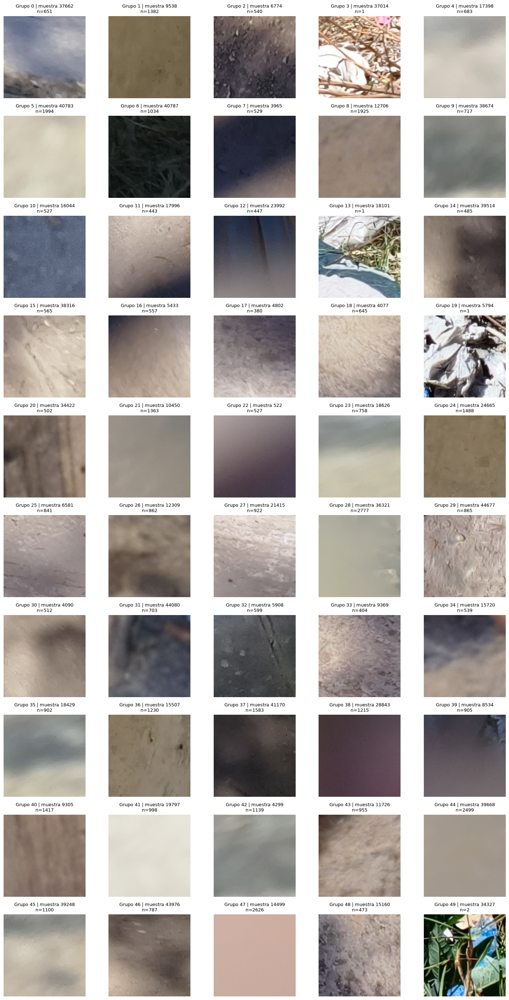

In [3]:
fig, ejes = plt.subplots(10, 5, figsize=(15, 28))
for grupo, eje in enumerate(ejes.flat):
    indice = int(indices_representantes[grupo])
    with Image.open(archivos_entrenamiento[indice]) as foto:
        eje.imshow(foto)
    eje.set_title(f"Grupo {grupo} | muestra {indice}\nn={conteos_grupos[grupo]}", fontsize=9)
    eje.axis("off")

plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados, "representantes_k_050.png"), dpi=150)
plt.show()
plt.close(fig)


## 18. Recuperar K=6 sin volver a entrenar




In [4]:
import os
import json
import hashlib
import gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

%matplotlib inline

carpeta_proyecto_6 = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado"
carpeta_tratada_6 = os.path.join(carpeta_proyecto_6, "dataset ya tratado")
carpeta_resultados_6 = os.path.join(carpeta_proyecto_6, "resultados eleccion k")
ruta_modelo_6 = os.path.join(carpeta_resultados_6, "modelos", "kmeans_006.npz")

with open(os.path.join(carpeta_proyecto_6, "division_fotos.json"), encoding="utf-8") as archivo:
    division_6 = json.load(archivo)
with open(os.path.join(carpeta_resultados_6, "muestra_entrenamiento.json"), encoding="utf-8") as archivo:
    muestra_relativa_6 = json.load(archivo)
with open(os.path.join(carpeta_resultados_6, "configuracion_modelos.json"), encoding="utf-8") as archivo:
    configuracion_6 = json.load(archivo)

huella_muestra_6 = hashlib.sha256("\n".join(muestra_relativa_6).encode("utf-8")).hexdigest()
if len(muestra_relativa_6) != 45000 or huella_muestra_6 != configuracion_6["huella_muestra"]:
    raise ValueError("La muestra no coincide con las 45.000 imagenes del modelo guardado.")
origenes_muestra_6 = {nombre.split("/")[0] for nombre in muestra_relativa_6}
if (set(division_6["entrenamiento"]) & set(division_6["prueba"])
        or not origenes_muestra_6.issubset(set(division_6["entrenamiento"]))):
    raise ValueError("Las fotos de entrenamiento y prueba deben permanecer separadas.")

archivos_entrenamiento_6 = [os.path.join(carpeta_tratada_6, nombre) for nombre in muestra_relativa_6]
with np.load(ruta_modelo_6, allow_pickle=False) as datos_modelo_6:
    centroides_6 = datos_modelo_6["centroides"]
    grupos_6 = datos_modelo_6["etiquetas"]
if centroides_6.shape != (6, 49152) or grupos_6.shape != (45000,):
    raise ValueError("El archivo no corresponde a K=6 con las 45.000 imagenes esperadas.")
if np.any(grupos_6 < 0) or np.any(grupos_6 >= 6):
    raise ValueError("El modelo contiene identificadores de grupos inesperados.")
conteos_6 = np.bincount(grupos_6, minlength=6)
if np.any(conteos_6 == 0):
    raise ValueError("Un grupo esta vacio; no se puede elegir su representante.")
with open(ruta_modelo_6, "rb") as archivo:
    huella_modelo_6 = hashlib.sha256(archivo.read()).hexdigest()

print("K=6 recuperado, sin volver a entrenar.")
print("Recortes de entrenamiento:", len(archivos_entrenamiento_6))
print("Fotos reservadas para prueba:", len(division_6["prueba"]))


K=6 recuperado, sin volver a entrenar.
Recortes de entrenamiento: 45000
Fotos reservadas para prueba: 20


## 19. Seleccionar y mostrar las seis imágenes representativas



Revisadas 1000/45000 imagenes
Revisadas 2000/45000 imagenes
Revisadas 3000/45000 imagenes
Revisadas 4000/45000 imagenes
Revisadas 5000/45000 imagenes
Revisadas 6000/45000 imagenes
Revisadas 7000/45000 imagenes
Revisadas 8000/45000 imagenes
Revisadas 9000/45000 imagenes
Revisadas 10000/45000 imagenes
Revisadas 11000/45000 imagenes
Revisadas 12000/45000 imagenes
Revisadas 13000/45000 imagenes
Revisadas 14000/45000 imagenes
Revisadas 15000/45000 imagenes
Revisadas 16000/45000 imagenes
Revisadas 17000/45000 imagenes
Revisadas 18000/45000 imagenes
Revisadas 19000/45000 imagenes
Revisadas 20000/45000 imagenes
Revisadas 21000/45000 imagenes
Revisadas 22000/45000 imagenes
Revisadas 23000/45000 imagenes
Revisadas 24000/45000 imagenes
Revisadas 25000/45000 imagenes
Revisadas 26000/45000 imagenes
Revisadas 27000/45000 imagenes
Revisadas 28000/45000 imagenes
Revisadas 29000/45000 imagenes
Revisadas 30000/45000 imagenes
Revisadas 31000/45000 imagenes
Revisadas 32000/45000 imagenes
Revisadas 33000/4

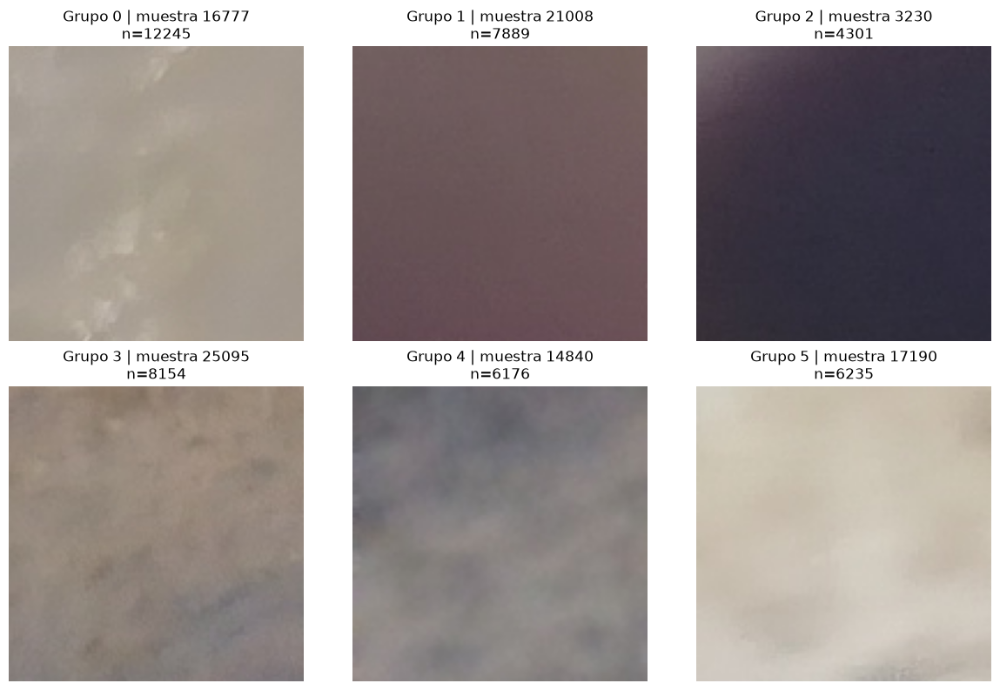

0 = limpio | 1 = basura | -1 = pendiente

etiquetas_manuales_6 = {
    0: -1,  # muestra 16777
    1: -1,  # muestra 21008
    2: -1,  # muestra 3230
    3: -1,  # muestra 25095
    4: -1,  # muestra 14840
    5: -1,  # muestra 17190
}


In [5]:
ruta_representantes_6 = os.path.join(carpeta_resultados_6, "representantes_k_006.npz")
recuperados_6 = False
if os.path.isfile(ruta_representantes_6):
    with np.load(ruta_representantes_6, allow_pickle=False) as datos_representantes_6:
        if (str(datos_representantes_6["huella_muestra"]) == huella_muestra_6
                and str(datos_representantes_6["huella_modelo"]) == huella_modelo_6):
            indices_representantes_6 = datos_representantes_6["indices_representantes"]
            distancias_6 = datos_representantes_6["distancias_al_centro"]
            recuperados_6 = True
    if recuperados_6:
        print("Las seis representantes se recuperaron del archivo guardado.")

if not recuperados_6:
    distancias_6 = np.empty(len(archivos_entrenamiento_6), dtype=np.float32)
    for indice_6, ruta_6 in enumerate(archivos_entrenamiento_6):
        with Image.open(ruta_6) as foto:
            if foto.size != (128, 128):
                raise ValueError(f"El recorte no mide 128 x 128: {ruta_6}")
            vector_6 = np.asarray(foto.convert("RGB"), dtype=np.float32).reshape(-1) / 255.0
        distancias_6[indice_6] = np.linalg.norm(vector_6 - centroides_6[grupos_6[indice_6]])
        if (indice_6 + 1) % 1000 == 0:
            print(f"Revisadas {indice_6 + 1}/45000 imagenes", flush=True)

    indices_representantes_6 = np.empty(6, dtype=np.int32)
    for grupo_6 in range(6):
        miembros_6 = np.flatnonzero(grupos_6 == grupo_6)
        indices_representantes_6[grupo_6] = miembros_6[np.argmin(distancias_6[miembros_6])]
    ruta_temporal_6 = ruta_representantes_6 + ".tmp.npz"
    np.savez_compressed(
        ruta_temporal_6, indices_representantes=indices_representantes_6,
        distancias_al_centro=distancias_6,
        huella_muestra=huella_muestra_6, huella_modelo=huella_modelo_6
    )
    os.replace(ruta_temporal_6, ruta_representantes_6)
    gc.collect()

if indices_representantes_6.shape != (6,) or distancias_6.shape != (45000,):
    raise ValueError("El archivo de representantes de K=6 tiene un tamano inesperado.")
if not np.array_equal(grupos_6[indices_representantes_6], np.arange(6)):
    raise ValueError("Las representantes no corresponden a sus grupos.")

fig, ejes = plt.subplots(2, 3, figsize=(12, 8))
for grupo_6, eje in enumerate(ejes.flat):
    indice_6 = int(indices_representantes_6[grupo_6])
    with Image.open(archivos_entrenamiento_6[indice_6]) as foto:
        eje.imshow(foto)
    eje.set_title(f"Grupo {grupo_6} | muestra {indice_6}\nn={conteos_6[grupo_6]}")
    eje.axis("off")
plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados_6, "representantes_k_006.png"), dpi=150)
plt.show()
plt.close(fig)

print("0 = limpio | 1 = basura | -1 = pendiente\n")
print("etiquetas_manuales_6 = {")
for grupo_6, indice_6 in enumerate(indices_representantes_6):
    print(f"    {grupo_6}: -1,  # muestra {int(indice_6)}")
print("}")


## 20. Escribir y guardar las seis etiquetas manuales




In [ ]:
etiquetas_manuales_6 = {
    0: -1,  
    1: -1,  
    2: -1,  
    3: -1,  
    4: -1,  
    5: -1,  
}

ruta_etiquetas_6 = os.path.join(carpeta_resultados_6, "etiquetas_representantes_k_006.json")
etiquetas_guardadas_6 = {}
if os.path.isfile(ruta_etiquetas_6):
    with open(ruta_etiquetas_6, encoding="utf-8") as archivo:
        guardadas_6 = json.load(archivo)
    if (guardadas_6["huella_muestra"] != huella_muestra_6
            or guardadas_6["huella_modelo"] != huella_modelo_6
            or guardadas_6["indices_representantes"] != indices_representantes_6.tolist()
            or guardadas_6["clases"] != {"0": "limpio", "1": "basura"}):
        raise ValueError("Las etiquetas guardadas no corresponden a estas representantes y clases.")
    etiquetas_guardadas_6 = {int(grupo): valor for grupo, valor in guardadas_6["etiquetas"].items()}
    if set(etiquetas_guardadas_6) != set(range(6)) or any(valor not in (-1, 0, 1) for valor in etiquetas_guardadas_6.values()):
        raise ValueError("Revisa el archivo de etiquetas guardadas de K=6.")

if set(etiquetas_manuales_6) != set(range(6)) or any(valor not in (-1, 0, 1) for valor in etiquetas_manuales_6.values()):
    raise ValueError("Completa los grupos 0 a 5 usando -1, 0 o 1.")
etiquetas_representantes_6 = {}
for grupo_6 in range(6):
    valor_6 = etiquetas_manuales_6[grupo_6]
    if valor_6 == -1:
        valor_6 = etiquetas_guardadas_6.get(grupo_6, -1)
    etiquetas_representantes_6[grupo_6] = int(valor_6)

datos_etiquetas_6 = {
    "clases": {0: "limpio", 1: "basura"},
    "huella_muestra": huella_muestra_6, "huella_modelo": huella_modelo_6,
    "indices_representantes": indices_representantes_6.tolist(),
    "etiquetas": etiquetas_representantes_6,
}
with open(ruta_etiquetas_6 + ".tmp", "w", encoding="utf-8") as archivo:
    json.dump(datos_etiquetas_6, archivo, ensure_ascii=False, indent=2)
os.replace(ruta_etiquetas_6 + ".tmp", ruta_etiquetas_6)

pendientes_6 = [grupo for grupo, valor in etiquetas_representantes_6.items() if valor == -1]
y_representantes_6 = None
if pendientes_6:
    print("Progreso guardado. Grupos pendientes:", pendientes_6)
else:
    y_representantes_6 = np.array([etiquetas_representantes_6[grupo] for grupo in range(6)], dtype=np.int64)
    print("Las seis etiquetas estan completas:", y_representantes_6)
print("etiquetas_manuales_6 = {")
for grupo_6, indice_6 in enumerate(indices_representantes_6):
    print(f"    {grupo_6}: {etiquetas_representantes_6[grupo_6]},  # muestra {int(indice_6)}")
print("}")
print("Archivo guardado:", ruta_etiquetas_6)


## 21. Preparar una muestra fija de 100 imágenes para testeo manual




In [6]:
import os
import json
import random
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

%matplotlib inline

carpeta_proyecto_test = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado"
carpeta_datos_test = os.path.join(carpeta_proyecto_test, "dataset ya tratado")
carpeta_testeo_manual = os.path.join(carpeta_proyecto_test, "testeo manual")
os.makedirs(carpeta_testeo_manual, exist_ok=True)
recortes_por_foto_test = 5
semilla_test = 42

with open(os.path.join(carpeta_proyecto_test, "division_fotos.json"), encoding="utf-8") as archivo:
    division_test = json.load(archivo)
fotos_reservadas_test = sorted(division_test["prueba"])
if set(fotos_reservadas_test) & set(division_test["entrenamiento"]):
    raise ValueError("Las fotos de testeo deben estar separadas de entrenamiento.")

ruta_muestra_test = os.path.join(carpeta_testeo_manual, "muestra_testeo.json")
if os.path.isfile(ruta_muestra_test):
    with open(ruta_muestra_test, encoding="utf-8") as archivo:
        datos_muestra_test = json.load(archivo)
    if (datos_muestra_test["fotos_prueba"] != fotos_reservadas_test
            or datos_muestra_test["recortes_por_foto"] != recortes_por_foto_test
            or datos_muestra_test["semilla"] != semilla_test):
        raise ValueError("Ya hay una muestra fija guardada. Conserva su configuracion para reutilizar el mismo testeo.")
    muestra_relativa_test = datos_muestra_test["archivos"]
    print("Muestra de testeo recuperada del archivo guardado.")
else:
    generador_test = random.Random(semilla_test)
    muestra_relativa_test = []
    for origen_test in fotos_reservadas_test:
        carpeta_origen_test = os.path.join(carpeta_datos_test, origen_test)
        recortes_test = sorted(nombre for nombre in os.listdir(carpeta_origen_test) if nombre.lower().endswith(".png"))
        if len(recortes_test) < recortes_por_foto_test:
            raise ValueError(f"Faltan recortes en la foto reservada: {origen_test}")
        elegidos_test = generador_test.sample(recortes_test, recortes_por_foto_test)
        muestra_relativa_test.extend(f"{origen_test}/{nombre}" for nombre in elegidos_test)
    datos_muestra_test = {
        "semilla": semilla_test, "recortes_por_foto": recortes_por_foto_test,
        "fotos_prueba": fotos_reservadas_test, "archivos": muestra_relativa_test,
    }
    with open(ruta_muestra_test, "x", encoding="utf-8") as archivo:
        json.dump(datos_muestra_test, archivo, ensure_ascii=False, indent=2)
    print("Muestra de testeo guardada.")

cantidad_test = len(muestra_relativa_test)
origenes_test = {nombre.split("/")[0] for nombre in muestra_relativa_test}
if (cantidad_test != len(fotos_reservadas_test) * recortes_por_foto_test
        or len(set(muestra_relativa_test)) != cantidad_test
        or origenes_test != set(fotos_reservadas_test)):
    raise ValueError("La muestra guardada no coincide con las fotos y la cantidad de recortes reservados.")
archivos_testeo = [os.path.join(carpeta_datos_test, nombre) for nombre in muestra_relativa_test]
huella_testeo = hashlib.sha256("\n".join(muestra_relativa_test).encode("utf-8")).hexdigest()
print("Fotos originales reservadas:", len(fotos_reservadas_test))
print("Imagenes para etiquetar manualmente:", cantidad_test)
print("Los indices Test 0 a", cantidad_test - 1, "mantendran este orden.")


Muestra de testeo guardada.
Fotos originales reservadas: 20
Imagenes para etiquetar manualmente: 100
Los indices Test 0 a 99 mantendran este orden.


## 22. Ver las imágenes de testeo y copiar su diccionario




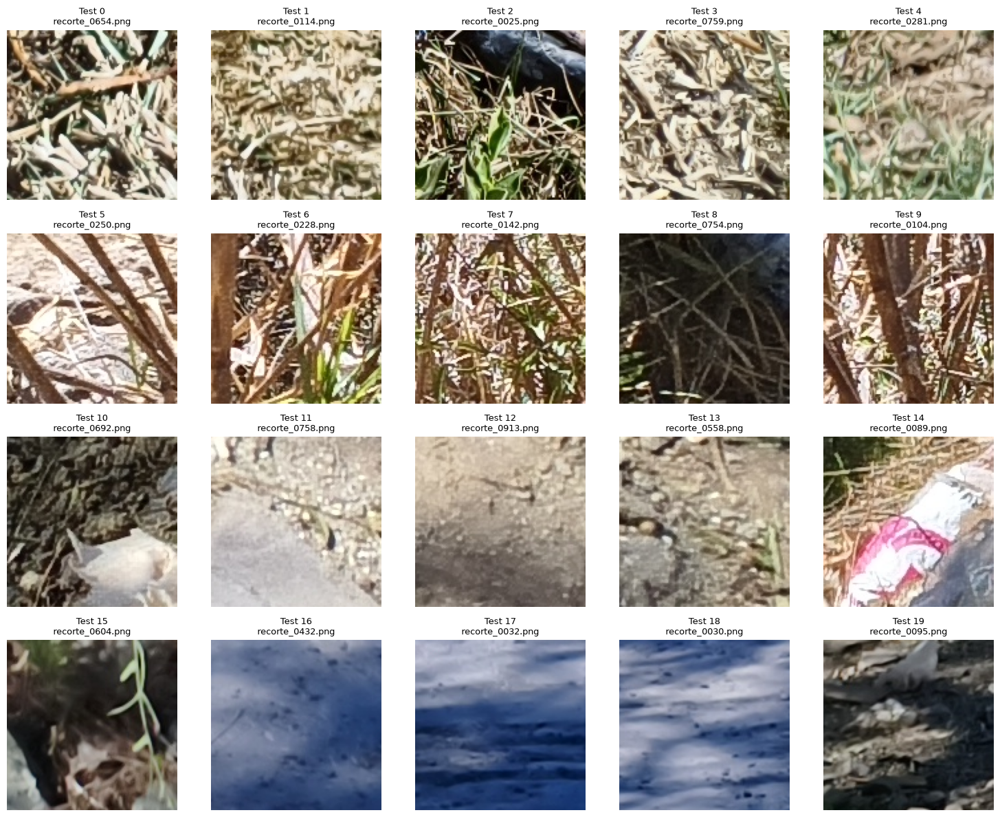

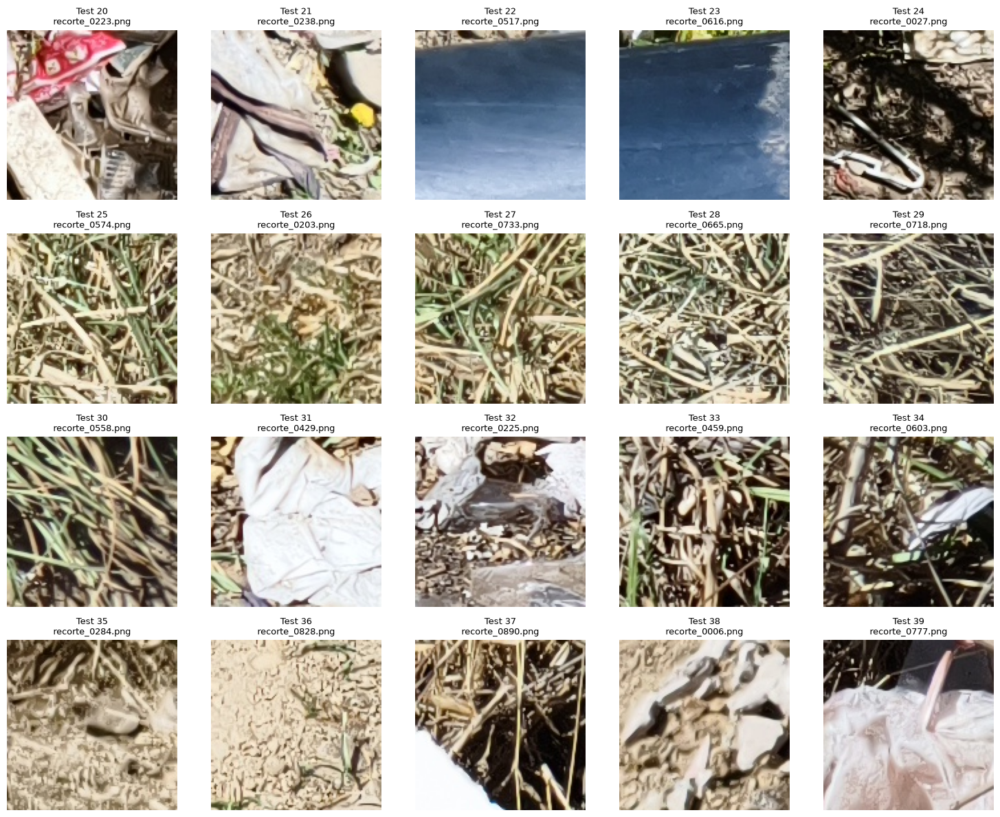

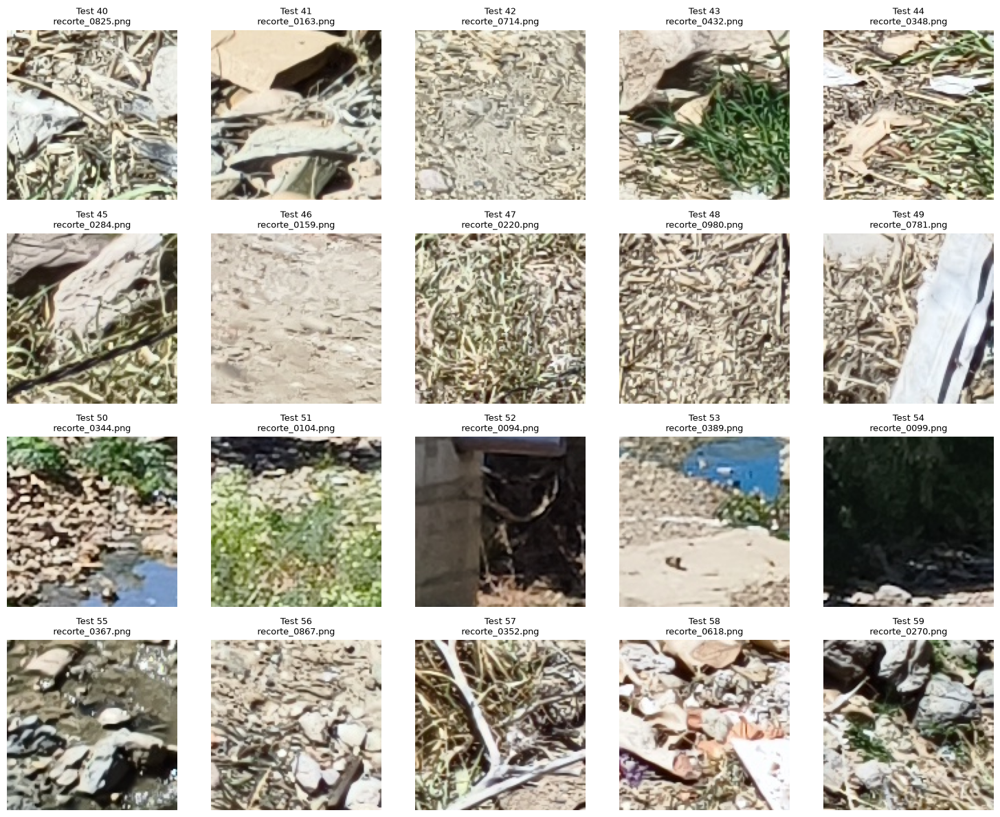

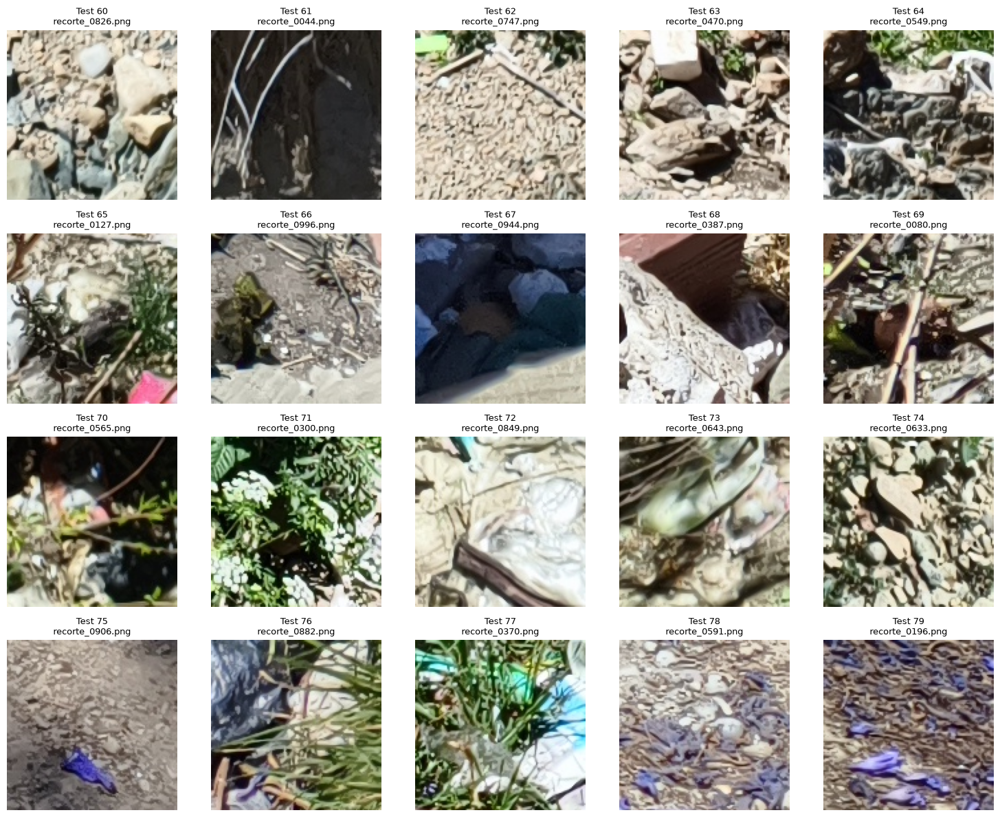

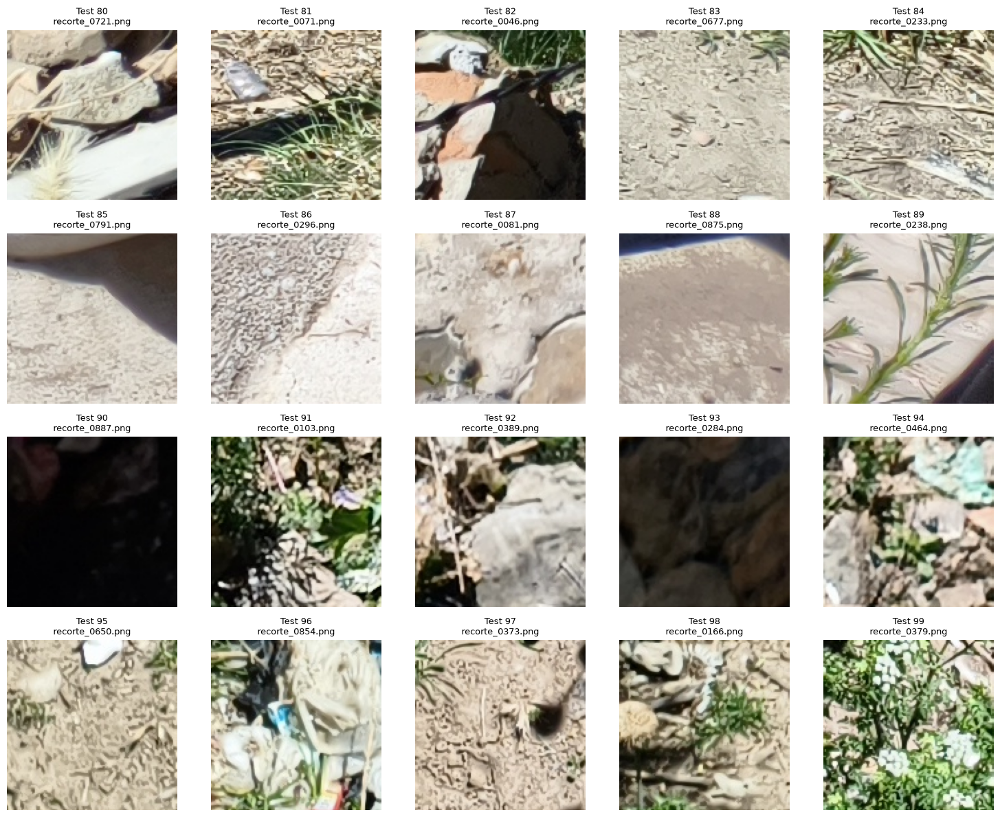

etiquetas_manuales_test = {
    0: -1,
    1: -1,
    2: -1,
    3: -1,
    4: -1,
    5: -1,
    6: -1,
    7: -1,
    8: -1,
    9: -1,
    10: -1,
    11: -1,
    12: -1,
    13: -1,
    14: -1,
    15: -1,
    16: -1,
    17: -1,
    18: -1,
    19: -1,
    20: -1,
    21: -1,
    22: -1,
    23: -1,
    24: -1,
    25: -1,
    26: -1,
    27: -1,
    28: -1,
    29: -1,
    30: -1,
    31: -1,
    32: -1,
    33: -1,
    34: -1,
    35: -1,
    36: -1,
    37: -1,
    38: -1,
    39: -1,
    40: -1,
    41: -1,
    42: -1,
    43: -1,
    44: -1,
    45: -1,
    46: -1,
    47: -1,
    48: -1,
    49: -1,
    50: -1,
    51: -1,
    52: -1,
    53: -1,
    54: -1,
    55: -1,
    56: -1,
    57: -1,
    58: -1,
    59: -1,
    60: -1,
    61: -1,
    62: -1,
    63: -1,
    64: -1,
    65: -1,
    66: -1,
    67: -1,
    68: -1,
    69: -1,
    70: -1,
    71: -1,
    72: -1,
    73: -1,
    74: -1,
    75: -1,
    76: -1,
    77: -1,
    78: -1,
    79: -1,
    80: -1,
    81: -1

In [7]:
imagenes_por_pagina_test = 20
for inicio_test in range(0, cantidad_test, imagenes_por_pagina_test):
    indices_pagina_test = list(range(inicio_test, min(inicio_test + imagenes_por_pagina_test, cantidad_test)))
    filas_test = (len(indices_pagina_test) + 4) // 5
    fig, ejes = plt.subplots(filas_test, 5, figsize=(15, 3 * filas_test), squeeze=False)
    for eje in ejes.flat:
        eje.axis("off")
    for eje, indice_test in zip(ejes.flat, indices_pagina_test):
        with Image.open(archivos_testeo[indice_test]) as foto:
            eje.imshow(foto)
        eje.set_title(f"Test {indice_test}\n{os.path.basename(archivos_testeo[indice_test])}", fontsize=9)
    plt.tight_layout()
    pagina_test = inicio_test // imagenes_por_pagina_test + 1
    fig.savefig(os.path.join(carpeta_testeo_manual, f"testeo_pagina_{pagina_test:02d}.png"), dpi=150)
    plt.show()
    plt.close(fig)

print("etiquetas_manuales_test = {")
for indice_test in range(cantidad_test):
    print(f"    {indice_test}: -1,")
print("}")


## 23. Escribir y guardar las etiquetas verdaderas de testeo




In [ ]:

etiquetas_manuales_test = {
    0: 0,
    1: 0,
    2: 1,
    3: 0,
    4: 0,
    5: 0,
    6: 0,
    7: 0,
    8: 0,
    9: 0,
    10: 1,
    11: 1,
    12: 0,
    13: 0,
    14: 1,
    15: 1,
    16: 0,
    17: 0,
    18: 0,
    19: 1,
    20: 1,
    21: 1,
    22: 0,
    23: 0,
    24: 1,
    25: 0,
    26: 0,
    27: 0,
    28: 0,
    29: 0,
    30: 0,
    31: 1,
    32: 1,
    33: 0,
    34: 1,
    35: 0,
    36: 0,
    37: 1,
    38: 1,
    39: 1,
    40: 1,
    41: 1,
    42: 0,
    43: 0,
    44: 1,
    45: 1,
    46: 0,
    47: 0,
    48: 0,
    49: 1,
    50: 0,
    51: 0,
    52: 0,
    53: 0,
    54: 0,
    55: 0,
    56: 0,
    57: 0,
    58: 1,
    59: 0,
    60: 0,
    61: 0,
    62: 0,
    63: 0,
    64: 1,
    65: 1,
    66: 1,
    67: 0,
    68: 0,
    69: 0,
    70: 0,
    71: 0,
    72: 1,
    73: 1,
    74: 0,
    75: 1,
    76: 1,
    77: 1,
    78: 0,
    79: 0,
    80: 1,
    81: 1,
    82: 0,
    83: 0,
    84: 1,
    85: 0,
    86: 0,
    87: 0,
    88: 0,
    89: 0,
    90: 0,
    91: 0,
    92: 0,
    93: 0,
    94: 1,
    95: 0,
    96: 1,
    97: 0,
    98: 0,
    99: 0,
}

ruta_etiquetas_test = os.path.join(carpeta_testeo_manual, "etiquetas_testeo.json")
etiquetas_guardadas_test = {}
if os.path.isfile(ruta_etiquetas_test):
    with open(ruta_etiquetas_test, encoding="utf-8") as archivo:
        datos_etiquetas_test = json.load(archivo)
    if (datos_etiquetas_test["huella_testeo"] != huella_testeo
            or datos_etiquetas_test["clases"] != {"0": "limpio", "1": "basura"}):
        raise ValueError("Las etiquetas guardadas pertenecen a otra muestra o utilizan otras clases.")
    etiquetas_guardadas_test = {int(indice): valor for indice, valor in datos_etiquetas_test["etiquetas"].items()}
    if set(etiquetas_guardadas_test) != set(range(cantidad_test)) or any(valor not in (-1, 0, 1) for valor in etiquetas_guardadas_test.values()):
        raise ValueError("Revisa las etiquetas guardadas del testeo.")

if set(etiquetas_manuales_test) != set(range(cantidad_test)) or any(valor not in (-1, 0, 1) for valor in etiquetas_manuales_test.values()):
    raise ValueError("Usa una entrada por imagen de testeo con valores -1, 0 o 1. Puedes copiar la plantilla de la seccion 22.")
etiquetas_testeo = {}
for indice_test in range(cantidad_test):
    valor_test = etiquetas_manuales_test[indice_test]
    if valor_test == -1:
        valor_test = etiquetas_guardadas_test.get(indice_test, -1)
    etiquetas_testeo[indice_test] = int(valor_test)

datos_para_guardar_test = {
    "clases": {0: "limpio", 1: "basura"},
    "huella_testeo": huella_testeo, "etiquetas": etiquetas_testeo,
}
with open(ruta_etiquetas_test + ".tmp", "w", encoding="utf-8") as archivo:
    json.dump(datos_para_guardar_test, archivo, ensure_ascii=False, indent=2)
os.replace(ruta_etiquetas_test + ".tmp", ruta_etiquetas_test)

pendientes_test = [indice for indice, valor in etiquetas_testeo.items() if valor == -1]
y_testeo = None
print("Testeo limpio:", sum(valor == 0 for valor in etiquetas_testeo.values()))
print("Testeo con basura:", sum(valor == 1 for valor in etiquetas_testeo.values()))
if pendientes_test:
    print("Progreso guardado. Imagenes pendientes:", pendientes_test)
else:
    y_testeo = np.array([etiquetas_testeo[indice] for indice in range(cantidad_test)], dtype=np.int64)
    print("Todas las etiquetas verdaderas de testeo estan completas.")
print("etiquetas_manuales_test = {")
for indice_test in range(cantidad_test):
    print(f"    {indice_test}: {etiquetas_testeo[indice_test]},")
print("}")
print("Archivo guardado:", ruta_etiquetas_test)


Testeo limpio: 66
Testeo con basura: 34
Todas las etiquetas verdaderas de testeo estan completas.
etiquetas_manuales_test = {
    0: 0,
    1: 0,
    2: 1,
    3: 0,
    4: 0,
    5: 0,
    6: 0,
    7: 0,
    8: 0,
    9: 0,
    10: 1,
    11: 1,
    12: 0,
    13: 0,
    14: 1,
    15: 1,
    16: 0,
    17: 0,
    18: 0,
    19: 1,
    20: 1,
    21: 1,
    22: 0,
    23: 0,
    24: 1,
    25: 0,
    26: 0,
    27: 0,
    28: 0,
    29: 0,
    30: 0,
    31: 1,
    32: 1,
    33: 0,
    34: 1,
    35: 0,
    36: 0,
    37: 1,
    38: 1,
    39: 1,
    40: 1,
    41: 1,
    42: 0,
    43: 0,
    44: 1,
    45: 1,
    46: 0,
    47: 0,
    48: 0,
    49: 1,
    50: 0,
    51: 0,
    52: 0,
    53: 0,
    54: 0,
    55: 0,
    56: 0,
    57: 0,
    58: 1,
    59: 0,
    60: 0,
    61: 0,
    62: 0,
    63: 0,
    64: 1,
    65: 1,
    66: 1,
    67: 0,
    68: 0,
    69: 0,
    70: 0,
    71: 0,
    72: 1,
    73: 1,
    74: 0,
    75: 1,
    76: 1,
    77: 1,
    78: 0,
    79: 0,
    

## 24. K=50: elegir una imagen de distancia intermedia por grupo




In [10]:
import os
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

%matplotlib inline

carpeta_proyecto_medios = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado"
carpeta_datos_medios = os.path.join(carpeta_proyecto_medios, "dataset ya tratado")
carpeta_resultados_medios = os.path.join(carpeta_proyecto_medios, "resultados eleccion k")
ruta_modelo_medios = os.path.join(carpeta_resultados_medios, "modelos", "kmeans_050.npz")
ruta_distancias_medios = os.path.join(carpeta_resultados_medios, "representantes_k_050.npz")
if not os.path.isfile(ruta_distancias_medios):
    raise ValueError("Primero ejecuta las secciones 15 y 16 para recuperar las distancias de K=50, sin entrenar.")

with open(os.path.join(carpeta_resultados_medios, "muestra_entrenamiento.json"), encoding="utf-8") as archivo:
    muestra_relativa_medios = json.load(archivo)
huella_muestra_medios = hashlib.sha256("\n".join(muestra_relativa_medios).encode("utf-8")).hexdigest()
with open(ruta_modelo_medios, "rb") as archivo:
    huella_modelo_medios = hashlib.sha256(archivo.read()).hexdigest()
with np.load(ruta_modelo_medios, allow_pickle=False) as datos_modelo_medios:
    grupos_base_50 = datos_modelo_medios["etiquetas"]
with np.load(ruta_distancias_medios, allow_pickle=False) as datos_distancias_medios:
    if (str(datos_distancias_medios["huella_muestra"]) != huella_muestra_medios
            or str(datos_distancias_medios["huella_modelo"]) != huella_modelo_medios):
        raise ValueError("Las distancias no corresponden al modelo y la muestra actuales de K=50.")
    distancias_base_50 = datos_distancias_medios["distancias_al_centro"]
    indices_cercanos_base_50 = datos_distancias_medios["indices_representantes"]

if len(muestra_relativa_medios) != 45000 or grupos_base_50.shape != (45000,) or distancias_base_50.shape != (45000,):
    raise ValueError("Se necesitan la misma muestra y las distancias de las 45.000 imagenes.")
if np.any(grupos_base_50 < 0) or np.any(grupos_base_50 >= 50) or not np.all(np.isfinite(distancias_base_50)):
    raise ValueError("Revisa los grupos y las distancias guardadas.")
conteos_medios_50 = np.bincount(grupos_base_50, minlength=50)
if np.any(conteos_medios_50 == 0):
    raise ValueError("Un grupo esta vacio; no tiene una imagen para mostrar.")
archivos_entrenamiento_medios = [os.path.join(carpeta_datos_medios, nombre) for nombre in muestra_relativa_medios]

indices_medios_50 = np.empty(50, dtype=np.int32)
medianas_distancias_50 = np.empty(50, dtype=np.float32)
for grupo_medio in range(50):
    miembros_medios = np.flatnonzero(grupos_base_50 == grupo_medio)
    distancias_grupo_medio = distancias_base_50[miembros_medios]
    mediana_grupo = np.median(distancias_grupo_medio)
    posicion_media = np.argmin(np.abs(distancias_grupo_medio - mediana_grupo))
    indices_medios_50[grupo_medio] = miembros_medios[posicion_media]
    medianas_distancias_50[grupo_medio] = mediana_grupo

ruta_seleccion_medios = os.path.join(carpeta_resultados_medios, "representantes_medios_k_050.npz")
np.savez_compressed(
    ruta_seleccion_medios + ".tmp.npz", indices_representantes=indices_medios_50,
    medianas_distancias=medianas_distancias_50,
    criterio="mediana_distancia", huella_muestra=huella_muestra_medios,
    huella_modelo=huella_modelo_medios
)
os.replace(ruta_seleccion_medios + ".tmp.npz", ruta_seleccion_medios)

lista_medios_50 = []
for grupo_medio, indice_medio in enumerate(indices_medios_50):
    lista_medios_50.append({
        "grupo": grupo_medio, "indice_muestra": int(indice_medio),
        "archivo": muestra_relativa_medios[indice_medio],
        "distancia_al_centro": float(distancias_base_50[indice_medio]),
        "mediana_distancias_grupo": float(medianas_distancias_50[grupo_medio]),
        "cantidad_en_grupo": int(conteos_medios_50[grupo_medio]),
    })
with open(os.path.join(carpeta_resultados_medios, "representantes_medios_k_050.json"), "w", encoding="utf-8") as archivo:
    json.dump({
        "criterio": "mediana_distancia", "huella_muestra": huella_muestra_medios,
        "huella_modelo": huella_modelo_medios, "representantes": lista_medios_50,
    }, archivo, ensure_ascii=False, indent=2)

print("Seleccionadas 50 imagenes: una de distancia intermedia por grupo.")
print("Distintas de la seleccion mas cercana:", int(np.count_nonzero(indices_medios_50 != indices_cercanos_base_50)))
print("Grupos que solo contienen una imagen:", np.flatnonzero(conteos_medios_50 == 1).tolist())


Seleccionadas 50 imagenes: una de distancia intermedia por grupo.
Distintas de la seleccion mas cercana: 46
Grupos que solo contienen una imagen: [3, 13, 19]


## 25. Ver las 50 imágenes intermedias y copiar el diccionario




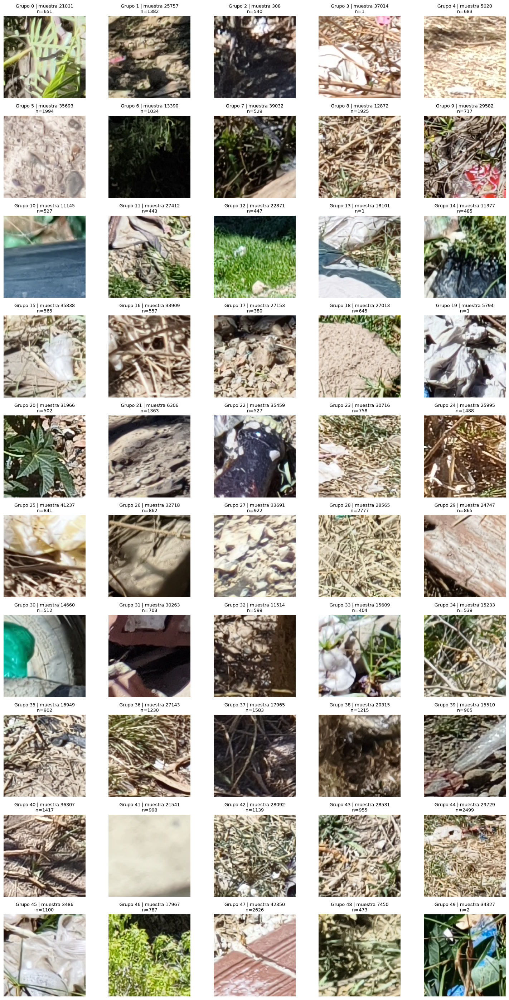

etiquetas_manuales_medios_50 = {
    0: -1,  # muestra 21031
    1: -1,  # muestra 25757
    2: -1,  # muestra 308
    3: -1,  # muestra 37014
    4: -1,  # muestra 5020
    5: -1,  # muestra 35693
    6: -1,  # muestra 13390
    7: -1,  # muestra 39032
    8: -1,  # muestra 12872
    9: -1,  # muestra 29582
    10: -1,  # muestra 11145
    11: -1,  # muestra 27412
    12: -1,  # muestra 22871
    13: -1,  # muestra 18101
    14: -1,  # muestra 11377
    15: -1,  # muestra 35838
    16: -1,  # muestra 33909
    17: -1,  # muestra 27153
    18: -1,  # muestra 27013
    19: -1,  # muestra 5794
    20: -1,  # muestra 31966
    21: -1,  # muestra 6306
    22: -1,  # muestra 35459
    23: -1,  # muestra 30716
    24: -1,  # muestra 25995
    25: -1,  # muestra 41237
    26: -1,  # muestra 32718
    27: -1,  # muestra 33691
    28: -1,  # muestra 28565
    29: -1,  # muestra 24747
    30: -1,  # muestra 14660
    31: -1,  # muestra 30263
    32: -1,  # muestra 11514
    33: -1,  # muestra 15

In [11]:
fig, ejes = plt.subplots(10, 5, figsize=(15, 28))
for grupo_medio, eje in enumerate(ejes.flat):
    indice_medio = int(indices_medios_50[grupo_medio])
    with Image.open(archivos_entrenamiento_medios[indice_medio]) as foto:
        eje.imshow(foto)
    eje.set_title(f"Grupo {grupo_medio} | muestra {indice_medio}\nn={conteos_medios_50[grupo_medio]}", fontsize=9)
    eje.axis("off")
plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados_medios, "representantes_medios_k_050.png"), dpi=150)
plt.show()
plt.close(fig)

print("etiquetas_manuales_medios_50 = {")
for grupo_medio, indice_medio in enumerate(indices_medios_50):
    print(f"    {grupo_medio}: -1,  # muestra {int(indice_medio)}")
print("}")


## 26. Etiquetar manualmente las imágenes intermedias de K=50



In [12]:
etiquetas_manuales_medios_50 = {
    0: 0,
    1: 1,
    2: 0,
    3: 1,
    4: 0,
    5: 0,
    6: 0,
    7: 1,
    8: 0,
    9: 1,
    10: 1,
    11: 1,
    12: 0,
    13: 1,
    14: 1,
    15: 1,
    16: 1,
    17: 0,
    18: 0,
    19: 1,
    20: 0,
    21: 0,
    22: 1,
    23: 1,
    24: 1,
    25: 1,
    26: 0,
    27: 0,
    28: 0,
    29: 0,
    30: 1,
    31: 0,
    32: 0,
    33: 1,
    34: 0,
    35: 1,
    36: 0,
    37: 0,
    38: 0,
    39: 1,
    40: 0,
    41: 0,
    42: 0,
    43: 0,
    44: 1,
    45: 1,
    46: 0,
    47: 0,
    48: 0,
    49: 1,
}
ruta_etiquetas_medios = os.path.join(carpeta_resultados_medios, "etiquetas_representantes_medios_k_050.json")
etiquetas_guardadas_medios = {}
if os.path.isfile(ruta_etiquetas_medios):
    with open(ruta_etiquetas_medios, encoding="utf-8") as archivo:
        datos_etiquetas_medios = json.load(archivo)
    if (datos_etiquetas_medios["huella_muestra"] != huella_muestra_medios
            or datos_etiquetas_medios["huella_modelo"] != huella_modelo_medios
            or datos_etiquetas_medios["indices_representantes"] != indices_medios_50.tolist()
            or datos_etiquetas_medios["criterio"] != "mediana_distancia"
            or datos_etiquetas_medios["clases"] != {"0": "limpio", "1": "basura"}):
        raise ValueError("Las etiquetas guardadas no corresponden a esta seleccion intermedia y sus clases.")
    etiquetas_guardadas_medios = {int(grupo): valor for grupo, valor in datos_etiquetas_medios["etiquetas"].items()}
    if set(etiquetas_guardadas_medios) != set(range(50)) or any(valor not in (-1, 0, 1) for valor in etiquetas_guardadas_medios.values()):
        raise ValueError("Revisa las etiquetas guardadas de las imagenes intermedias.")

if set(etiquetas_manuales_medios_50) != set(range(50)) or any(valor not in (-1, 0, 1) for valor in etiquetas_manuales_medios_50.values()):
    raise ValueError("Completa los grupos 0 a 49 usando -1, 0 o 1.")
etiquetas_representantes_medios_50 = {}
for grupo_medio in range(50):
    valor_medio = etiquetas_manuales_medios_50[grupo_medio]
    if valor_medio == -1:
        valor_medio = etiquetas_guardadas_medios.get(grupo_medio, -1)
    etiquetas_representantes_medios_50[grupo_medio] = int(valor_medio)

datos_para_guardar_medios = {
    "clases": {0: "limpio", 1: "basura"}, "criterio": "mediana_distancia",
    "huella_muestra": huella_muestra_medios, "huella_modelo": huella_modelo_medios,
    "indices_representantes": indices_medios_50.tolist(),
    "etiquetas": etiquetas_representantes_medios_50,
}
with open(ruta_etiquetas_medios + ".tmp", "w", encoding="utf-8") as archivo:
    json.dump(datos_para_guardar_medios, archivo, ensure_ascii=False, indent=2)
os.replace(ruta_etiquetas_medios + ".tmp", ruta_etiquetas_medios)

pendientes_medios = [grupo for grupo, valor in etiquetas_representantes_medios_50.items() if valor == -1]
y_representantes_medios_50 = None
print("Representantes limpios:", sum(valor == 0 for valor in etiquetas_representantes_medios_50.values()))
print("Representantes con basura:", sum(valor == 1 for valor in etiquetas_representantes_medios_50.values()))
if pendientes_medios:
    print("Progreso guardado. Grupos pendientes:", pendientes_medios)
else:
    y_representantes_medios_50 = np.array([etiquetas_representantes_medios_50[grupo] for grupo in range(50)], dtype=np.int64)
    print("Las 50 etiquetas de las imagenes intermedias estan completas.")
print("etiquetas_manuales_medios_50 = {")
for grupo_medio, indice_medio in enumerate(indices_medios_50):
    print(f"    {grupo_medio}: {etiquetas_representantes_medios_50[grupo_medio]},  # muestra {int(indice_medio)}")
print("}")
print("Archivo guardado:", ruta_etiquetas_medios)


Representantes limpios: 28
Representantes con basura: 22
Las 50 etiquetas de las imagenes intermedias estan completas.
etiquetas_manuales_medios_50 = {
    0: 0,  # muestra 21031
    1: 1,  # muestra 25757
    2: 0,  # muestra 308
    3: 1,  # muestra 37014
    4: 0,  # muestra 5020
    5: 0,  # muestra 35693
    6: 0,  # muestra 13390
    7: 1,  # muestra 39032
    8: 0,  # muestra 12872
    9: 1,  # muestra 29582
    10: 1,  # muestra 11145
    11: 1,  # muestra 27412
    12: 0,  # muestra 22871
    13: 1,  # muestra 18101
    14: 1,  # muestra 11377
    15: 1,  # muestra 35838
    16: 1,  # muestra 33909
    17: 0,  # muestra 27153
    18: 0,  # muestra 27013
    19: 1,  # muestra 5794
    20: 0,  # muestra 31966
    21: 0,  # muestra 6306
    22: 1,  # muestra 35459
    23: 1,  # muestra 30716
    24: 1,  # muestra 25995
    25: 1,  # muestra 41237
    26: 0,  # muestra 32718
    27: 0,  # muestra 33691
    28: 0,  # muestra 28565
    29: 0,  # muestra 24747
    30: 1,  # muestra 1

## 27. Preparar PyTorch para la RTX 3060




In [13]:
%pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cu126 --disable-pip-version-check


Looking in indexes: https://download.pytorch.org/whl/cu126
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB 1.9 MB/s eta 0:23:20
   ---------------------------------------- 0.0/2.6 GB 2.6 MB/s eta 0:16:23
   ---------------------------------------- 0.0/2.6 GB 2.6 MB/s eta 0:16:33
   ---------------------------------------- 0.0/2.6 GB 2.9 MB/s eta 0:15:09
   ---------------------------------------- 0.0/2.6 GB 2.5 MB/s eta 0:17:14
   ---------------------------------------- 0.0/2.6 GB 2.3 MB/s eta 0:18:52
   ---------------------------------------- 0.0/2.6 GB 2.3 MB/s eta 0:18:34
   ---------------------------------------- 0.0/2.6 GB 2.1 MB/s eta 0:21:06
   ---------------------------------------- 0.0/2.6 GB 2.2 MB/s eta 0:19:56
   ---------------------------------------- 0.0/2.6 GB 2.2 MB/s eta 0:19:18
   ---------------------------------------- 0.0/2.6 GB 2.3 MB/s eta 0:18:28
   ---------------------------------

In [14]:
import os
import json
import csv
import time
import hashlib
import gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn

%matplotlib inline

if not torch.cuda.is_available():
    raise RuntimeError("CUDA no esta disponible. Instala PyTorch con CUDA en este kernel y reinicialo si hace falta. No se entrenara en CPU.")
dispositivo_clf = torch.device("cuda")
print("PyTorch:", torch.__version__)
print("CUDA de PyTorch:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))

semilla_clf = 42
iteraciones_clf = 2500
tasa_clf = 0.0001
lote_clf = 256
umbral_clf = 0.5
forzar_reentrenamiento_clf = False

carpeta_proyecto_clf = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado"
carpeta_imagenes_clf = os.path.join(carpeta_proyecto_clf, "dataset ya tratado")
carpeta_kmeans_clf = os.path.join(carpeta_proyecto_clf, "resultados eleccion k")
carpeta_test_clf = os.path.join(carpeta_proyecto_clf, "testeo manual")
carpeta_salida_clf = os.path.join(carpeta_proyecto_clf, "resultados clasificacion")
os.makedirs(carpeta_salida_clf, exist_ok=True)


PyTorch: 2.14.1+cu126
CUDA de PyTorch: 12.6
GPU: NVIDIA GeForce RTX 3060


## 28. Recuperar las 50 etiquetas manuales y el mismo testeo




In [15]:
with open(os.path.join(carpeta_proyecto_clf, "division_fotos.json"), encoding="utf-8") as archivo:
    division_clf = json.load(archivo)
with open(os.path.join(carpeta_kmeans_clf, "muestra_entrenamiento.json"), encoding="utf-8") as archivo:
    muestra_train_clf = json.load(archivo)
with open(os.path.join(carpeta_kmeans_clf, "etiquetas_representantes_medios_k_050.json"), encoding="utf-8") as archivo:
    manuales_clf = json.load(archivo)
with open(os.path.join(carpeta_test_clf, "muestra_testeo.json"), encoding="utf-8") as archivo:
    muestra_test_clf = json.load(archivo)["archivos"]
with open(os.path.join(carpeta_test_clf, "etiquetas_testeo.json"), encoding="utf-8") as archivo:
    verdaderas_test_clf = json.load(archivo)

ruta_kmeans_clf = os.path.join(carpeta_kmeans_clf, "modelos", "kmeans_050.npz")
with open(ruta_kmeans_clf, "rb") as archivo:
    huella_modelo_clf = hashlib.sha256(archivo.read()).hexdigest()
huella_train_clf = hashlib.sha256("\n".join(muestra_train_clf).encode("utf-8")).hexdigest()
huella_test_clf = hashlib.sha256("\n".join(muestra_test_clf).encode("utf-8")).hexdigest()

if (manuales_clf["huella_modelo"] != huella_modelo_clf
        or manuales_clf["huella_muestra"] != huella_train_clf
        or manuales_clf["criterio"] != "mediana_distancia"
        or manuales_clf["clases"] != {"0": "limpio", "1": "basura"}):
    raise ValueError("Las etiquetas manuales no corresponden a esta muestra y a la seleccion intermedia de K=50.")
if verdaderas_test_clf["huella_testeo"] != huella_test_clf or verdaderas_test_clf["clases"] != {"0": "limpio", "1": "basura"}:
    raise ValueError("Las etiquetas de testeo no corresponden a las imagenes guardadas.")
if len(muestra_train_clf) != 45000 or len(muestra_test_clf) != 100:
    raise ValueError("Se esperan las 45.000 imagenes de entrenamiento y las 100 de testeo guardadas.")
if set(manuales_clf["etiquetas"]) != {str(i) for i in range(50)} or set(verdaderas_test_clf["etiquetas"]) != {str(i) for i in range(100)}:
    raise ValueError("Faltan entradas en los diccionarios de etiquetas.")
if any(valor not in (0, 1) for valor in manuales_clf["etiquetas"].values()) or any(valor not in (0, 1) for valor in verdaderas_test_clf["etiquetas"].values()):
    raise ValueError("Completa todas las etiquetas con 0 o 1 antes de entrenar.")

origenes_train_clf = {nombre.split("/")[0] for nombre in muestra_train_clf}
origenes_test_clf = {nombre.split("/")[0] for nombre in muestra_test_clf}
if (set(division_clf["entrenamiento"]) & set(division_clf["prueba"])
        or origenes_train_clf & origenes_test_clf
        or not origenes_train_clf.issubset(set(division_clf["entrenamiento"]))
        or origenes_test_clf != set(division_clf["prueba"])):
    raise ValueError("El entrenamiento y el testeo deben conservar sus fotos de origen separadas.")

indices_manuales_clf = np.array(manuales_clf["indices_representantes"], dtype=np.int64)
with np.load(ruta_kmeans_clf, allow_pickle=False) as datos:
    grupos_clf = datos["etiquetas"]
with np.load(os.path.join(carpeta_kmeans_clf, "representantes_medios_k_050.npz"), allow_pickle=False) as datos:
    indices_guardados_clf = datos["indices_representantes"]
if (indices_manuales_clf.shape != (50,) or grupos_clf.shape != (45000,)
        or not np.array_equal(indices_manuales_clf, indices_guardados_clf)):
    raise ValueError("Los indices manuales no coinciden con los representantes guardados.")
if np.any(grupos_clf < 0) or np.any(grupos_clf >= 50) or not np.array_equal(grupos_clf[indices_manuales_clf], np.arange(50)):
    raise ValueError("Revisa la relacion entre los 50 representantes y sus grupos.")

etiquetas_manual_clf = np.array([manuales_clf["etiquetas"][str(i)] for i in range(50)], dtype=np.int64)
etiquetas_test_clf = np.array([verdaderas_test_clf["etiquetas"][str(i)] for i in range(100)], dtype=np.int64)
archivos_train_clf = [os.path.join(carpeta_imagenes_clf, nombre) for nombre in muestra_train_clf]
archivos_manual_clf = [archivos_train_clf[indice] for indice in indices_manuales_clf]
archivos_test_clf = [os.path.join(carpeta_imagenes_clf, nombre) for nombre in muestra_test_clf]

configuracion_comun_clf = {
    "modelo": "regresion_logistica", "entradas": 49152, "salidas": 1,
    "escala": "RGB dividido entre 255", "semilla": semilla_clf,
    "iteraciones": iteraciones_clf, "tasa": tasa_clf, "lote_maximo": lote_clf,
    "huella_muestra": huella_train_clf, "huella_kmeans": huella_modelo_clf,
}
print("Entrenamiento inicial:", len(archivos_manual_clf), "imagenes con etiquetas manuales.")
print("Limpias:", int(np.sum(etiquetas_manual_clf == 0)), "| Con basura:", int(np.sum(etiquetas_manual_clf == 1)))
print("Testeo fijo:", len(archivos_test_clf), "imagenes con etiquetas verdaderas.")


Entrenamiento inicial: 50 imagenes con etiquetas manuales.
Limpias: 28 | Con basura: 22
Testeo fijo: 100 imagenes con etiquetas verdaderas.


## 29. Funciones para cargar, entrenar y evaluar en CUDA




In [16]:
def cargar_imagenes_cuda(rutas, nombre):
    print(f"Cargando {len(rutas)} imagenes para {nombre}...", flush=True)
    inicio_carga = time.perf_counter()
    pixeles_cuda = torch.empty((len(rutas), 49152), dtype=torch.uint8, device=dispositivo_clf)
    for inicio in range(0, len(rutas), lote_clf):
        fin = min(inicio + lote_clf, len(rutas))
        lote_cpu = np.empty((fin - inicio, 49152), dtype=np.uint8)
        for posicion, ruta in enumerate(rutas[inicio:fin]):
            with Image.open(ruta) as foto:
                if foto.size != (128, 128):
                    raise ValueError(f"La imagen no mide 128 x 128: {ruta}")
                lote_cpu[posicion] = np.asarray(foto.convert("RGB"), dtype=np.uint8).reshape(-1)
        pixeles_cuda[inicio:fin] = torch.from_numpy(lote_cpu).to(dispositivo_clf)
        if fin == len(rutas) or fin % (20 * lote_clf) == 0:
            print(f"Cargadas {fin}/{len(rutas)}", flush=True)
    torch.cuda.synchronize()
    print(f"Carga y transferencia: {time.perf_counter() - inicio_carga:.1f} segundos.")
    return pixeles_cuda


In [17]:
def entrenar_logistica_cuda(rutas, etiquetas, nombre, nombre_archivo):
    configuracion = configuracion_comun_clf.copy()
    configuracion["etapa"] = nombre
    configuracion["cantidad_imagenes"] = len(rutas)
    configuracion["huella_archivos"] = hashlib.sha256("\n".join(rutas).encode("utf-8")).hexdigest()
    configuracion["huella_etiquetas"] = hashlib.sha256(np.asarray(etiquetas, dtype=np.uint8).tobytes()).hexdigest()
    ruta_checkpoint = os.path.join(carpeta_salida_clf, nombre_archivo)

    torch.manual_seed(semilla_clf)
    modelo = nn.Linear(49152, 1).to(dispositivo_clf)
    nn.init.zeros_(modelo.weight)
    nn.init.zeros_(modelo.bias)
    if os.path.isfile(ruta_checkpoint) and not forzar_reentrenamiento_clf:
        guardado = torch.load(ruta_checkpoint, map_location=dispositivo_clf, weights_only=True)
        if guardado["configuracion"] == configuracion:
            modelo.load_state_dict(guardado["pesos"])
            print(nombre, ": modelo recuperado, sin volver a entrenar.")
            return modelo, guardado["historial"], float(guardado["segundos_entrenamiento"])
        print("Las etiquetas o la configuracion cambiaron; se realizara un ajuste nuevo.")

    pixeles_cuda = cargar_imagenes_cuda(rutas, nombre)
    objetivos_cuda = torch.tensor(etiquetas, dtype=torch.float32, device=dispositivo_clf).reshape(-1, 1)
    costo = nn.BCEWithLogitsLoss()
    optimizador = torch.optim.SGD(modelo.parameters(), lr=tasa_clf)
    historial = []
    tamano_lote = min(lote_clf, len(rutas))
    if iteraciones_clf < (len(rutas) + tamano_lote - 1) // tamano_lote:
        raise ValueError("Aumenta las iteraciones para recorrer al menos una vez todas las imagenes.")
    posicion = len(rutas)
    modelo.train()
    torch.cuda.synchronize()
    inicio_entrenamiento = time.perf_counter()

    for paso in range(iteraciones_clf):
        if posicion >= len(rutas):
            orden = torch.randperm(len(rutas), device=dispositivo_clf)
            posicion = 0
        indices_lote = orden[posicion:posicion + tamano_lote]
        posicion += tamano_lote
        entradas = pixeles_cuda[indices_lote].float().div_(255.0)
        objetivos = objetivos_cuda[indices_lote]

        optimizador.zero_grad(set_to_none=True)
        logits = modelo(entradas)
        perdida = costo(logits, objetivos)
        valor_costo = float(perdida.item())
        if not np.isfinite(valor_costo):
            raise ValueError("El costo dejo de ser finito. Revisa la tasa de aprendizaje antes de repetir.")
        perdida.backward()
        optimizador.step()
        historial.append(valor_costo)
        if (paso + 1) % 250 == 0 or paso == 0:
            print(f"{nombre}: iteracion {paso + 1}/{iteraciones_clf} | costo del lote={valor_costo:.5f}", flush=True)

    torch.cuda.synchronize()
    segundos = time.perf_counter() - inicio_entrenamiento
    torch.save({
        "pesos": modelo.state_dict(), "configuracion": configuracion,
        "historial": historial, "segundos_entrenamiento": segundos,
        "version_torch": str(torch.__version__),
    }, ruta_checkpoint + ".tmp")
    os.replace(ruta_checkpoint + ".tmp", ruta_checkpoint)
    del pixeles_cuda, objetivos_cuda, entradas, objetivos, logits, perdida, optimizador
    gc.collect()
    torch.cuda.empty_cache()
    print(f"{nombre}: entrenamiento terminado en {segundos / 60:.2f} minutos.")
    print("Pesos guardados en:", ruta_checkpoint)
    return modelo, historial, segundos


In [18]:
def evaluar_logistica_cuda(modelo, nombre):
    pixeles_test_cuda = cargar_imagenes_cuda(archivos_test_clf, "testeo")
    objetivos_test_cuda = torch.tensor(etiquetas_test_clf, dtype=torch.float32, device=dispositivo_clf).reshape(-1, 1)
    modelo.eval()
    with torch.no_grad():
        logits_test = modelo(pixeles_test_cuda.float().div_(255.0))
        perdida_test = float(nn.BCEWithLogitsLoss()(logits_test, objetivos_test_cuda).item())
        probabilidades = torch.sigmoid(logits_test).reshape(-1).cpu().numpy()
    predicciones = (probabilidades >= umbral_clf).astype(np.int64)
    tn = int(np.sum((etiquetas_test_clf == 0) & (predicciones == 0)))
    fp = int(np.sum((etiquetas_test_clf == 0) & (predicciones == 1)))
    fn = int(np.sum((etiquetas_test_clf == 1) & (predicciones == 0)))
    tp = int(np.sum((etiquetas_test_clf == 1) & (predicciones == 1)))
    exactitud = (tp + tn) / len(etiquetas_test_clf)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    metricas = {
        "etapa": nombre, "costo_test": perdida_test, "exactitud": exactitud,
        "precision_basura": precision, "recall_basura": recall, "f1_basura": f1,
        "limpio_correcto": tn, "limpio_marcado_basura": fp,
        "basura_no_detectada": fn, "basura_correcta": tp,
        "huella_testeo": huella_test_clf, "umbral": umbral_clf,
    }
    print(f"{nombre}: {tp + tn}/{len(etiquetas_test_clf)} aciertos | exactitud={exactitud:.2%}")
    print(f"Basura: precision={precision:.2%} | recall={recall:.2%} | F1={f1:.2%}")
    print("Imagenes con basura que el modelo marco como limpias:", fn)

    matriz = np.array([[tn, fp], [fn, tp]])
    fig, eje = plt.subplots(figsize=(5, 4))
    eje.imshow(matriz, cmap="Blues")
    for fila in range(2):
        for columna in range(2):
            color_texto = "white" if matriz[fila, columna] > matriz.max() / 2 else "black"
            eje.text(columna, fila, str(matriz[fila, columna]), ha="center", va="center", color=color_texto)
    eje.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Limpio", "Basura"],
            yticklabels=["Limpio", "Basura"], xlabel="Prediccion", ylabel="Etiqueta real", title=nombre)
    plt.tight_layout()
    fig.savefig(os.path.join(carpeta_salida_clf, f"matriz_{nombre}.png"), dpi=150)
    plt.show()
    plt.close(fig)

    with open(os.path.join(carpeta_salida_clf, f"predicciones_{nombre}.csv"), "w", newline="", encoding="utf-8") as archivo:
        escritor = csv.writer(archivo)
        escritor.writerow(["indice_test", "archivo", "etiqueta_real", "probabilidad_basura", "prediccion"])
        for indice in range(len(predicciones)):
            escritor.writerow([indice, muestra_test_clf[indice], int(etiquetas_test_clf[indice]), float(probabilidades[indice]), int(predicciones[indice])])
    with open(os.path.join(carpeta_salida_clf, f"metricas_{nombre}.json"), "w", encoding="utf-8") as archivo:
        json.dump(metricas, archivo, ensure_ascii=False, indent=2)
    del pixeles_test_cuda, objetivos_test_cuda, logits_test
    torch.cuda.empty_cache()
    return metricas


## 30. Entrenar primero con las 50 imágenes etiquetadas manualmente




Cargando 50 imagenes para 50_manuales...
Cargadas 50/50
Carga y transferencia: 0.1 segundos.
50_manuales: iteracion 1/2500 | costo del lote=0.69315
50_manuales: iteracion 250/2500 | costo del lote=0.47433
50_manuales: iteracion 500/2500 | costo del lote=0.36516
50_manuales: iteracion 750/2500 | costo del lote=0.29512
50_manuales: iteracion 1000/2500 | costo del lote=0.24655
50_manuales: iteracion 1250/2500 | costo del lote=0.21111
50_manuales: iteracion 1500/2500 | costo del lote=0.18424
50_manuales: iteracion 1750/2500 | costo del lote=0.16325
50_manuales: iteracion 2000/2500 | costo del lote=0.14642
50_manuales: iteracion 2250/2500 | costo del lote=0.13267
50_manuales: iteracion 2500/2500 | costo del lote=0.12122
50_manuales: entrenamiento terminado en 0.06 minutos.
Pesos guardados en: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados clasificacion\logistica_50_manuales.pt


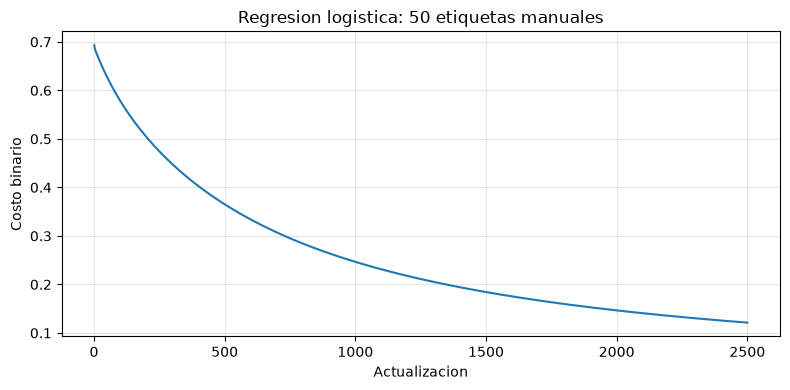

In [19]:
modelo_manual_clf, historial_manual_clf, segundos_manual_clf = entrenar_logistica_cuda(
    archivos_manual_clf, etiquetas_manual_clf,
    "50_manuales", "logistica_50_manuales.pt"
)

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(range(1, len(historial_manual_clf) + 1), historial_manual_clf)
eje.set(title="Regresion logistica: 50 etiquetas manuales", xlabel="Actualizacion", ylabel="Costo binario")
eje.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(carpeta_salida_clf, "costo_50_manuales.png"), dpi=150)
plt.show()
plt.close(fig)


## 31. Evaluar el primer modelo con las 100 imágenes de testeo



Cargando 100 imagenes para testeo...
Cargadas 100/100
Carga y transferencia: 0.3 segundos.
50_manuales: 56/100 aciertos | exactitud=56.00%
Basura: precision=35.29% | recall=35.29% | F1=35.29%
Imagenes con basura que el modelo marco como limpias: 22


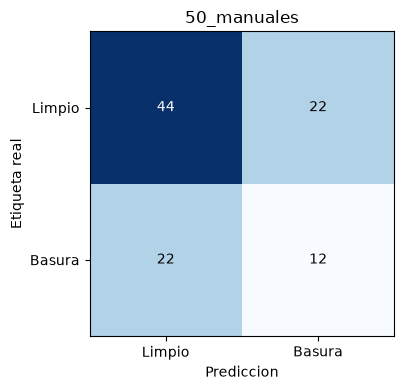

In [20]:
metricas_manual_clf = evaluar_logistica_cuda(modelo_manual_clf, "50_manuales")


## 32. Propagar las 50 etiquetas a las 45.000 imágenes de entrenamiento



In [21]:
etiquetas_propagadas_clf = etiquetas_manual_clf[grupos_clf]
if not np.array_equal(etiquetas_propagadas_clf[indices_manuales_clf], etiquetas_manual_clf):
    raise ValueError("Las etiquetas propagadas no conservan las etiquetas de los representantes.")

ruta_propagadas_clf = os.path.join(carpeta_salida_clf, "etiquetas_propagadas_k_050.npz")
np.savez_compressed(
    ruta_propagadas_clf + ".tmp.npz", etiquetas=etiquetas_propagadas_clf,
    indices_manuales=indices_manuales_clf,
    huella_muestra=huella_train_clf, huella_kmeans=huella_modelo_clf,
    huella_etiquetas_manuales=hashlib.sha256(etiquetas_manual_clf.astype(np.uint8).tobytes()).hexdigest()
)
os.replace(ruta_propagadas_clf + ".tmp.npz", ruta_propagadas_clf)

print("Total para el segundo entrenamiento:", len(etiquetas_propagadas_clf))
print("Etiquetas manuales:", len(indices_manuales_clf))
print("Etiquetas propagadas:", len(etiquetas_propagadas_clf) - len(indices_manuales_clf))
print("Limpio:", int(np.sum(etiquetas_propagadas_clf == 0)))
print("Basura:", int(np.sum(etiquetas_propagadas_clf == 1)))
print("Archivo guardado:", ruta_propagadas_clf)


Total para el segundo entrenamiento: 45000
Etiquetas manuales: 50
Etiquetas propagadas: 44950
Limpio: 29854
Basura: 15146
Archivo guardado: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados clasificacion\etiquetas_propagadas_k_050.npz


## 33. Entrenar un modelo nuevo con las 45.000 imágenes




Cargando 45000 imagenes para 45000_propagadas...
Cargadas 5120/45000
Cargadas 10240/45000
Cargadas 15360/45000
Cargadas 20480/45000
Cargadas 25600/45000
Cargadas 30720/45000
Cargadas 35840/45000
Cargadas 40960/45000
Cargadas 45000/45000
Carga y transferencia: 104.3 segundos.
45000_propagadas: iteracion 1/2500 | costo del lote=0.69315
45000_propagadas: iteracion 250/2500 | costo del lote=0.64073
45000_propagadas: iteracion 500/2500 | costo del lote=0.62052
45000_propagadas: iteracion 750/2500 | costo del lote=0.63475
45000_propagadas: iteracion 1000/2500 | costo del lote=0.60646
45000_propagadas: iteracion 1250/2500 | costo del lote=0.59459
45000_propagadas: iteracion 1500/2500 | costo del lote=0.62818
45000_propagadas: iteracion 1750/2500 | costo del lote=0.59921
45000_propagadas: iteracion 2000/2500 | costo del lote=0.61322
45000_propagadas: iteracion 2250/2500 | costo del lote=0.61589
45000_propagadas: iteracion 2500/2500 | costo del lote=0.60097
45000_propagadas: entrenamiento termi

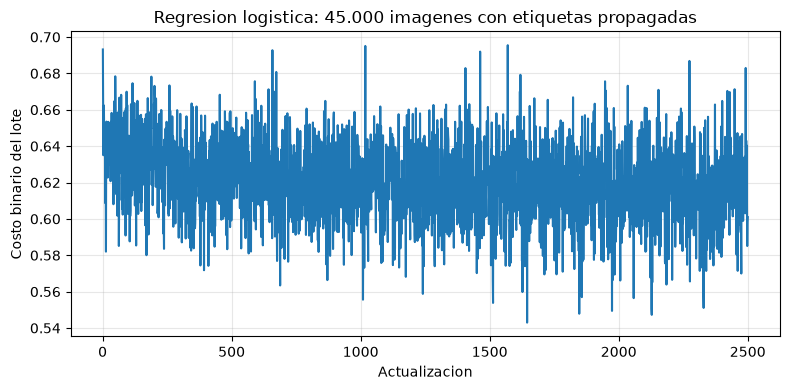

In [22]:
modelo_propagado_clf, historial_propagado_clf, segundos_propagado_clf = entrenar_logistica_cuda(
    archivos_train_clf, etiquetas_propagadas_clf,
    "45000_propagadas", "logistica_45000_propagadas.pt"
)

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(range(1, len(historial_propagado_clf) + 1), historial_propagado_clf)
eje.set(title="Regresion logistica: 45.000 imagenes con etiquetas propagadas", xlabel="Actualizacion", ylabel="Costo binario del lote")
eje.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(carpeta_salida_clf, "costo_45000_propagadas.png"), dpi=150)
plt.show()
plt.close(fig)


## 34. Evaluar otra vez y comparar las dos etapas




Cargando 100 imagenes para testeo...
Cargadas 100/100
Carga y transferencia: 0.2 segundos.
45000_propagadas: 64/100 aciertos | exactitud=64.00%
Basura: precision=33.33% | recall=5.88% | F1=10.00%
Imagenes con basura que el modelo marco como limpias: 32


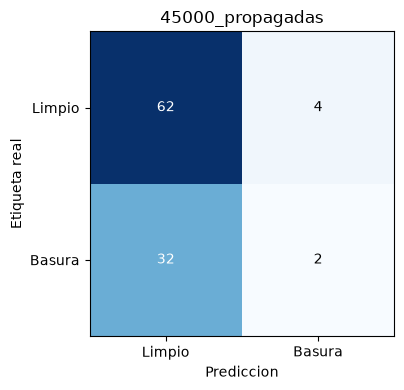

Etapa | Exactitud | Precision basura | Recall basura | F1 basura
50_manuales | 56.00% | 35.29% | 35.29% | 35.29%
45000_propagadas | 64.00% | 33.33% | 5.88% | 10.00%


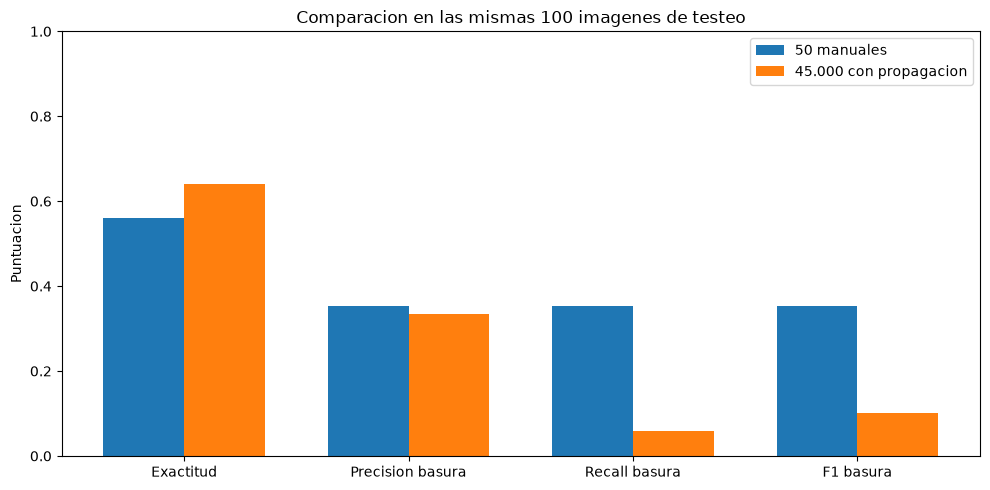

Resultados guardados en: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados clasificacion


In [23]:
metricas_propagado_clf = evaluar_logistica_cuda(modelo_propagado_clf, "45000_propagadas")

comparacion_clf = [metricas_manual_clf.copy(), metricas_propagado_clf.copy()]
comparacion_clf[0]["imagenes_entrenamiento"] = 50
comparacion_clf[0]["segundos_entrenamiento_guardado"] = segundos_manual_clf
comparacion_clf[1]["imagenes_entrenamiento"] = 45000
comparacion_clf[1]["segundos_entrenamiento_guardado"] = segundos_propagado_clf
with open(os.path.join(carpeta_salida_clf, "comparacion_modelos.csv"), "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(comparacion_clf[0]))
    escritor.writeheader()
    escritor.writerows(comparacion_clf)

print("Etapa | Exactitud | Precision basura | Recall basura | F1 basura")
for fila in comparacion_clf:
    print(f"{fila['etapa']} | {fila['exactitud']:.2%} | {fila['precision_basura']:.2%} | {fila['recall_basura']:.2%} | {fila['f1_basura']:.2%}")

nombres_metricas_clf = ["exactitud", "precision_basura", "recall_basura", "f1_basura"]
posiciones_clf = np.arange(len(nombres_metricas_clf))
fig, eje = plt.subplots(figsize=(10, 5))
eje.bar(posiciones_clf - 0.18, [metricas_manual_clf[nombre] for nombre in nombres_metricas_clf], width=0.36, label="50 manuales")
eje.bar(posiciones_clf + 0.18, [metricas_propagado_clf[nombre] for nombre in nombres_metricas_clf], width=0.36, label="45.000 con propagacion")
eje.set_xticks(posiciones_clf, ["Exactitud", "Precision basura", "Recall basura", "F1 basura"])
eje.set(title="Comparacion en las mismas 100 imagenes de testeo", ylabel="Puntuacion", ylim=(0, 1))
eje.legend()
plt.tight_layout()
fig.savefig(os.path.join(carpeta_salida_clf, "comparacion_modelos.png"), dpi=150)
plt.show()
plt.close(fig)
print("Resultados guardados en:", carpeta_salida_clf)


## 35. Preparación común del aprendizaje activo




In [28]:
necesarias_activo = ["archivos_train_clf", "etiquetas_manual_clf", "indices_manuales_clf", "grupos_clf",
                     "huella_train_clf", "huella_test_clf", "huella_modelo_clf", "cargar_imagenes_cuda",
                     "entrenar_logistica_cuda", "evaluar_logistica_cuda"]
if any(nombre not in globals() for nombre in necesarias_activo):
    raise ValueError("Ejecuta la configuracion de la seccion 27, los datos de la 28 y las funciones de la 29.")

consultas_por_ronda = 100
carpeta_activo = os.path.join(carpeta_salida_clf, "aprendizaje activo")
os.makedirs(carpeta_activo, exist_ok=True)

with np.load(os.path.join(carpeta_salida_clf, "etiquetas_propagadas_k_050.npz"), allow_pickle=False) as datos:
    if (str(datos["huella_muestra"]) != huella_train_clf
            or str(datos["huella_kmeans"]) != huella_modelo_clf
            or str(datos["huella_etiquetas_manuales"]) != hashlib.sha256(etiquetas_manual_clf.astype(np.uint8).tobytes()).hexdigest()):
        raise ValueError("La propagacion guardada no coincide con las etiquetas actuales.")
    etiquetas_base_activo = datos["etiquetas"].copy()
if etiquetas_base_activo.shape != (45000,) or not np.array_equal(etiquetas_base_activo[indices_manuales_clf], etiquetas_manual_clf):
    raise ValueError("Revisa las etiquetas propagadas y los 50 representantes manuales.")
correcciones_iniciales_activo = {
    int(indice): int(etiqueta) for indice, etiqueta in zip(indices_manuales_clf, etiquetas_manual_clf)
}
print("Preparacion lista. Continua con la ronda 1, secciones 36 a 39.")


Preparacion lista. Continua con la ronda 1, secciones 36 a 39.


In [29]:
def leer_etiquetas_activas(ruta, seleccion, exigir_completas=False):
    if not os.path.isfile(ruta):
        if exigir_completas:
            raise ValueError("Primero completa y guarda las etiquetas de la ronda anterior.")
        return {}
    with open(ruta, encoding="utf-8") as archivo:
        datos = json.load(archivo)
    if (datos["ronda"] != seleccion["ronda"] or datos["indices_train"] != seleccion["indices_train"]
            or datos["huella_modelo_origen"] != seleccion["huella_modelo_origen"]
            or datos["huella_muestra"] != huella_train_clf
            or datos["clases"] != {"0": "limpio", "1": "basura"}):
        raise ValueError("Las etiquetas guardadas pertenecen a otra seleccion de imagenes.")
    etiquetas = {int(indice): valor for indice, valor in datos["etiquetas"].items()}
    if set(etiquetas) != set(range(len(seleccion["indices_train"]))) or any(valor not in (-1, 0, 1) for valor in etiquetas.values()):
        raise ValueError("Revisa el diccionario guardado de esta ronda.")
    if exigir_completas and any(valor == -1 for valor in etiquetas.values()):
        raise ValueError("Completa las 100 etiquetas manuales de esta ronda antes de continuar.")
    return etiquetas

def probabilidades_cuda_activo(modelo, rutas, nombre):
    pixeles = cargar_imagenes_cuda(rutas, nombre)
    probabilidades_basura = np.empty(len(rutas), dtype=np.float32)
    modelo.eval()
    with torch.no_grad():
        for inicio in range(0, len(rutas), lote_clf):
            fin = min(inicio + lote_clf, len(rutas))
            logits = modelo(pixeles[inicio:fin].float().div_(255.0))
            probabilidades_basura[inicio:fin] = torch.sigmoid(logits).reshape(-1).cpu().numpy()
    del pixeles, logits
    torch.cuda.empty_cache()
    return probabilidades_basura

def resumen_confianza_activo(probabilidades_basura, reales=None):
    probabilidades = np.column_stack((1 - probabilidades_basura, probabilidades_basura))
    confianza = np.max(probabilidades, axis=1)
    predicciones = (probabilidades_basura >= umbral_clf).astype(np.int64)
    resumen = {
        "confianza_media": float(np.mean(confianza)),
        "probabilidad_basura_media": float(np.mean(probabilidades_basura)),
        "predicciones_basura": int(np.sum(predicciones == 1)),
    }
    if reales is not None:
        errores = predicciones != reales
        es_basura = reales == 1
        resumen["exactitud"] = float(np.mean(~errores))
        resumen["basura_real"] = int(np.sum(es_basura))
        resumen["confianza_media_errores"] = float(np.mean(confianza[errores])) if np.any(errores) else None
        resumen["confianza_media_basura_real"] = float(np.mean(confianza[es_basura])) if np.any(es_basura) else None
        resumen["probabilidad_basura_media_en_basura_real"] = float(np.mean(probabilidades_basura[es_basura])) if np.any(es_basura) else None
    return resumen


In [30]:
def seleccionar_consultas_activas(numero_ronda, correcciones_anteriores):
    carpeta_ronda_activa = os.path.join(carpeta_activo, f"ronda_{numero_ronda:02d}")
    os.makedirs(carpeta_ronda_activa, exist_ok=True)
    etiquetas_esperadas_origen = etiquetas_base_activo.copy()
    for indice_train, etiqueta in correcciones_anteriores.items():
        etiquetas_esperadas_origen[indice_train] = etiqueta
    if numero_ronda == 1:
        etapa_origen_activo = "45000_propagadas"
        ruta_origen_activo = os.path.join(carpeta_salida_clf, "logistica_45000_propagadas.pt")
    else:
        etapa_origen_activo = f"activo_ronda_{numero_ronda - 1:02d}"
        ruta_origen_activo = os.path.join(carpeta_salida_clf, f"logistica_activo_ronda_{numero_ronda - 1:02d}.pt")
    if not os.path.isfile(ruta_origen_activo):
        raise ValueError("Primero termina el entrenamiento de la etapa anterior.")
    guardado_origen_activo = torch.load(ruta_origen_activo, map_location=dispositivo_clf, weights_only=True)
    config_origen_activo = guardado_origen_activo["configuracion"]
    huella_etiquetas_origen = hashlib.sha256(etiquetas_esperadas_origen.astype(np.uint8).tobytes()).hexdigest()
    if (config_origen_activo["huella_etiquetas"] != huella_etiquetas_origen
            or config_origen_activo["huella_muestra"] != huella_train_clf
            or config_origen_activo["huella_kmeans"] != huella_modelo_clf
            or config_origen_activo["huella_archivos"] != hashlib.sha256("\n".join(archivos_train_clf).encode("utf-8")).hexdigest()):
        raise ValueError("El modelo anterior no coincide con los datos y las correcciones acumuladas. Revisa esa etapa.")
    modelo_origen_activo = nn.Linear(49152, 1).to(dispositivo_clf)
    modelo_origen_activo.load_state_dict(guardado_origen_activo["pesos"])
    with open(ruta_origen_activo, "rb") as archivo:
        huella_modelo_origen_activo = hashlib.sha256(archivo.read()).hexdigest()

    ruta_probabilidades_activo = os.path.join(carpeta_ronda_activa, "probabilidades_pool.npz")
    probabilidades_pool_activo = None
    if os.path.isfile(ruta_probabilidades_activo):
        with np.load(ruta_probabilidades_activo, allow_pickle=False) as datos:
            if str(datos["huella_modelo"]) == huella_modelo_origen_activo and str(datos["huella_muestra"]) == huella_train_clf:
                probabilidades_pool_activo = datos["probabilidades_basura"]
    if probabilidades_pool_activo is None:
        probabilidades_pool_activo = probabilidades_cuda_activo(modelo_origen_activo, archivos_train_clf, "seleccion activa")
        np.savez_compressed(ruta_probabilidades_activo + ".tmp.npz",
                            probabilidades_basura=probabilidades_pool_activo,
                            huella_modelo=huella_modelo_origen_activo, huella_muestra=huella_train_clf)
        os.replace(ruta_probabilidades_activo + ".tmp.npz", ruta_probabilidades_activo)

    if (probabilidades_pool_activo.shape != (len(archivos_train_clf),)
            or not np.all(np.isfinite(probabilidades_pool_activo))
            or np.any((probabilidades_pool_activo < 0) | (probabilidades_pool_activo > 1))):
        raise ValueError("Las probabilidades guardadas no son validas para las 45.000 imagenes.")
    probabilidades_clases_activo = np.column_stack((1 - probabilidades_pool_activo, probabilidades_pool_activo))
    confianza_de_cada_imagen = np.max(probabilidades_clases_activo, axis=1)
    posiciones_sin_etiqueta_verificada = np.setdiff1d(np.arange(len(archivos_train_clf)), list(correcciones_anteriores))
    orden_por_menor_confianza = np.argsort(confianza_de_cada_imagen[posiciones_sin_etiqueta_verificada])
    indices_propuestos_activo = posiciones_sin_etiqueta_verificada[orden_por_menor_confianza[:consultas_por_ronda]]

    ruta_seleccion_activo = os.path.join(carpeta_ronda_activa, "seleccion.json")
    if os.path.isfile(ruta_seleccion_activo):
        with open(ruta_seleccion_activo, encoding="utf-8") as archivo:
            seleccion_activa = json.load(archivo)
        if (seleccion_activa["ronda"] != numero_ronda or seleccion_activa["huella_muestra"] != huella_train_clf
                or seleccion_activa["huella_modelo_origen"] != huella_modelo_origen_activo
                or seleccion_activa["indices_train"] != indices_propuestos_activo.tolist()):
            raise ValueError("La seleccion guardada corresponde a otro modelo o a otras correcciones. Se conserva para no cambiar tus etiquetas.")
        print("Se recuperaron las mismas 100 consultas de esta ronda.")
    else:
        seleccion_activa = {
            "ronda": numero_ronda, "etapa_origen": etapa_origen_activo,
            "huella_muestra": huella_train_clf, "huella_modelo_origen": huella_modelo_origen_activo,
            "indices_train": indices_propuestos_activo.tolist(),
            "probabilidades_basura_antes": probabilidades_pool_activo[indices_propuestos_activo].tolist(),
            "confianzas_antes": confianza_de_cada_imagen[indices_propuestos_activo].tolist(),
        }
        with open(ruta_seleccion_activo, "x", encoding="utf-8") as archivo:
            json.dump(seleccion_activa, archivo, ensure_ascii=False, indent=2)
    indices_consulta_activo = np.array(seleccion_activa["indices_train"], dtype=np.int64)
    resumen_pool_activo = resumen_confianza_activo(probabilidades_pool_activo)
    print("Modelo usado para seleccionar:", etapa_origen_activo)
    print("Imagenes disponibles sin etiqueta manual:", len(posiciones_sin_etiqueta_verificada))
    print("Predicciones de basura en las 45.000:", resumen_pool_activo["predicciones_basura"])
    print(f"Confianza media en las 45.000: {resumen_pool_activo['confianza_media']:.2%}")
    print(f"Confianza media de las 100 seleccionadas: {np.mean(seleccion_activa['confianzas_antes']):.2%}")
    print("Estas cantidades son predicciones del modelo, no conteos de basura real.")
    return seleccion_activa


def mostrar_consultas_activas(seleccion_activa):
    numero_ronda = seleccion_activa["ronda"]
    carpeta_ronda_activa = os.path.join(carpeta_activo, f"ronda_{numero_ronda:02d}")
    indices_consulta_activo = np.array(seleccion_activa["indices_train"], dtype=np.int64)
    for inicio_consulta in range(0, consultas_por_ronda, 20):
        ids_pagina = list(range(inicio_consulta, min(inicio_consulta + 20, consultas_por_ronda)))
        fig, ejes = plt.subplots(4, 5, figsize=(15, 12))
        for eje in ejes.flat:
            eje.axis("off")
        for eje, identificador in zip(ejes.flat, ids_pagina):
            indice_train = int(indices_consulta_activo[identificador])
            with Image.open(archivos_train_clf[indice_train]) as foto:
                eje.imshow(foto)
            confianza = seleccion_activa["confianzas_antes"][identificador]
            eje.set_title(f"Ronda {numero_ronda} | ID {identificador} | muestra {indice_train}\nConfianza: {confianza:.2%}", fontsize=8)
        plt.tight_layout()
        fig.savefig(os.path.join(carpeta_ronda_activa, f"consultas_pagina_{inicio_consulta // 20 + 1:02d}.png"), dpi=150)
        plt.show()
        plt.close(fig)
    print(f"etiquetas_activo_{numero_ronda} = {{")
    for identificador, indice_train in enumerate(indices_consulta_activo):
        print(f"    {identificador}: -1,  # muestra {int(indice_train)}")
    print("}")


In [31]:
def leer_seleccion_activa(numero_ronda):
    ruta = os.path.join(carpeta_activo, f"ronda_{numero_ronda:02d}", "seleccion.json")
    if not os.path.isfile(ruta):
        raise ValueError("Primero muestra las 100 imagenes de esta ronda.")
    with open(ruta, encoding="utf-8") as archivo:
        seleccion = json.load(archivo)
    indices = seleccion["indices_train"]
    if (seleccion["ronda"] != numero_ronda or seleccion["huella_muestra"] != huella_train_clf
            or len(indices) != consultas_por_ronda or len(set(indices)) != consultas_por_ronda
            or any(indice < 0 or indice >= len(archivos_train_clf) for indice in indices)):
        raise ValueError("La seleccion no corresponde a esta ronda y muestra de entrenamiento.")
    return seleccion


def recuperar_correcciones_activas(numero_ronda, correcciones_anteriores):
    seleccion = leer_seleccion_activa(numero_ronda)
    ruta = os.path.join(carpeta_activo, f"ronda_{numero_ronda:02d}", "etiquetas.json")
    etiquetas = leer_etiquetas_activas(ruta, seleccion, True)
    correcciones = correcciones_anteriores.copy()
    for identificador, indice_train in enumerate(seleccion["indices_train"]):
        if indice_train in correcciones:
            raise ValueError("La ronda repite una imagen ya revisada manualmente.")
        correcciones[indice_train] = int(etiquetas[identificador])
    return seleccion, correcciones


def preparar_etiquetas_entrenamiento_activo(numero_ronda, correcciones):
    etiquetas = etiquetas_base_activo.copy()
    for indice_train, etiqueta in correcciones.items():
        etiquetas[indice_train] = etiqueta
    ruta = os.path.join(carpeta_activo, f"ronda_{numero_ronda:02d}", "etiquetas_entrenamiento.npz")
    np.savez_compressed(ruta + ".tmp.npz", etiquetas=etiquetas,
                        indices_manuales=np.array(sorted(correcciones), dtype=np.int64),
                        huella_muestra=huella_train_clf, huella_kmeans=huella_modelo_clf)
    os.replace(ruta + ".tmp.npz", ruta)
    print("Etiquetas humanas acumuladas:", len(correcciones))
    print("Etiquetas propagadas sustituidas:", int(np.sum(etiquetas != etiquetas_base_activo)))
    return etiquetas


def cargar_modelo_ronda_activa(numero_ronda):
    ruta_etiquetas = os.path.join(carpeta_activo, f"ronda_{numero_ronda:02d}", "etiquetas_entrenamiento.npz")
    ruta_modelo = os.path.join(carpeta_salida_clf, f"logistica_activo_ronda_{numero_ronda:02d}.pt")
    if not os.path.isfile(ruta_etiquetas) or not os.path.isfile(ruta_modelo):
        raise ValueError("Primero entrena y guarda el modelo de esta ronda.")
    with np.load(ruta_etiquetas, allow_pickle=False) as datos:
        if str(datos["huella_muestra"]) != huella_train_clf:
            raise ValueError("Las etiquetas guardadas corresponden a otra muestra.")
        etiquetas = datos["etiquetas"]
    guardado = torch.load(ruta_modelo, map_location=dispositivo_clf, weights_only=True)
    configuracion = guardado["configuracion"]
    if (configuracion["huella_muestra"] != huella_train_clf
            or configuracion["huella_kmeans"] != huella_modelo_clf
            or configuracion["huella_archivos"] != hashlib.sha256("\n".join(archivos_train_clf).encode("utf-8")).hexdigest()
            or configuracion["huella_etiquetas"] != hashlib.sha256(etiquetas.astype(np.uint8).tobytes()).hexdigest()):
        raise ValueError("El modelo guardado no coincide con las etiquetas y datos de esta ronda.")
    modelo = nn.Linear(49152, 1).to(dispositivo_clf)
    modelo.load_state_dict(guardado["pesos"])
    modelo.eval()
    print("Modelo recuperado del disco:", ruta_modelo)
    return modelo


def guardar_etiquetas_activas(numero_ronda, etiquetas_escritas_activo):
    seleccion_activa = leer_seleccion_activa(numero_ronda)
    carpeta_ronda_activa = os.path.join(carpeta_activo, f"ronda_{numero_ronda:02d}")
    huella_modelo_origen_activo = seleccion_activa["huella_modelo_origen"]
    indices_consulta_activo = np.array(seleccion_activa["indices_train"], dtype=np.int64)
    if set(etiquetas_escritas_activo) != set(range(consultas_por_ronda)) or any(valor not in (-1, 0, 1) for valor in etiquetas_escritas_activo.values()):
        raise ValueError("Completa los ID 0 a 99 de la ronda actual con -1, 0 o 1.")
    ruta_etiquetas_activo = os.path.join(carpeta_ronda_activa, "etiquetas.json")
    etiquetas_guardadas_activo = leer_etiquetas_activas(ruta_etiquetas_activo, seleccion_activa)
    etiquetas_consultas_activo = {}
    for identificador in range(consultas_por_ronda):
        valor = etiquetas_escritas_activo[identificador]
        if valor == -1:
            valor = etiquetas_guardadas_activo.get(identificador, -1)
        etiquetas_consultas_activo[identificador] = int(valor)
    datos_etiquetas_activo = {
        "ronda": numero_ronda, "clases": {0: "limpio", 1: "basura"},
        "huella_muestra": huella_train_clf,
        "huella_modelo_origen": huella_modelo_origen_activo,
        "indices_train": seleccion_activa["indices_train"], "etiquetas": etiquetas_consultas_activo,
    }
    with open(ruta_etiquetas_activo + ".tmp", "w", encoding="utf-8") as archivo:
        json.dump(datos_etiquetas_activo, archivo, ensure_ascii=False, indent=2)
    os.replace(ruta_etiquetas_activo + ".tmp", ruta_etiquetas_activo)
    pendientes_activo = [identificador for identificador, valor in etiquetas_consultas_activo.items() if valor == -1]
    print("Consultas limpias:", sum(valor == 0 for valor in etiquetas_consultas_activo.values()))
    print("Consultas con basura:", sum(valor == 1 for valor in etiquetas_consultas_activo.values()))
    if pendientes_activo:
        print("Progreso guardado. ID pendientes:", pendientes_activo)
    else:
        etiquetas_lote_activo = np.array([etiquetas_consultas_activo[i] for i in range(consultas_por_ronda)], dtype=np.int64)
        print("Las 100 etiquetas estan completas.")
        print("Pseudoetiquetas incorrectas encontradas en esta consulta:", int(np.sum(etiquetas_lote_activo != etiquetas_base_activo[indices_consulta_activo])))
    print(f"etiquetas_activo_{numero_ronda} = {{")
    for identificador, indice_train in enumerate(indices_consulta_activo):
        print(f"    {identificador}: {etiquetas_consultas_activo[identificador]},  # muestra {int(indice_train)}")
    print("}")
    return etiquetas_consultas_activo


## 36. Ronda 1: seleccionar las primeras 100 imágenes




In [32]:
seleccion_activo_1 = seleccionar_consultas_activas(1, correcciones_iniciales_activo)


Se recuperaron las mismas 100 consultas de esta ronda.
Modelo usado para seleccionar: 45000_propagadas
Imagenes disponibles sin etiqueta manual: 44950
Predicciones de basura en las 45.000: 2807
Confianza media en las 45.000: 67.79%
Confianza media de las 100 seleccionadas: 50.07%
Estas cantidades son predicciones del modelo, no conteos de basura real.


## 37. Ronda 1: ver las imágenes




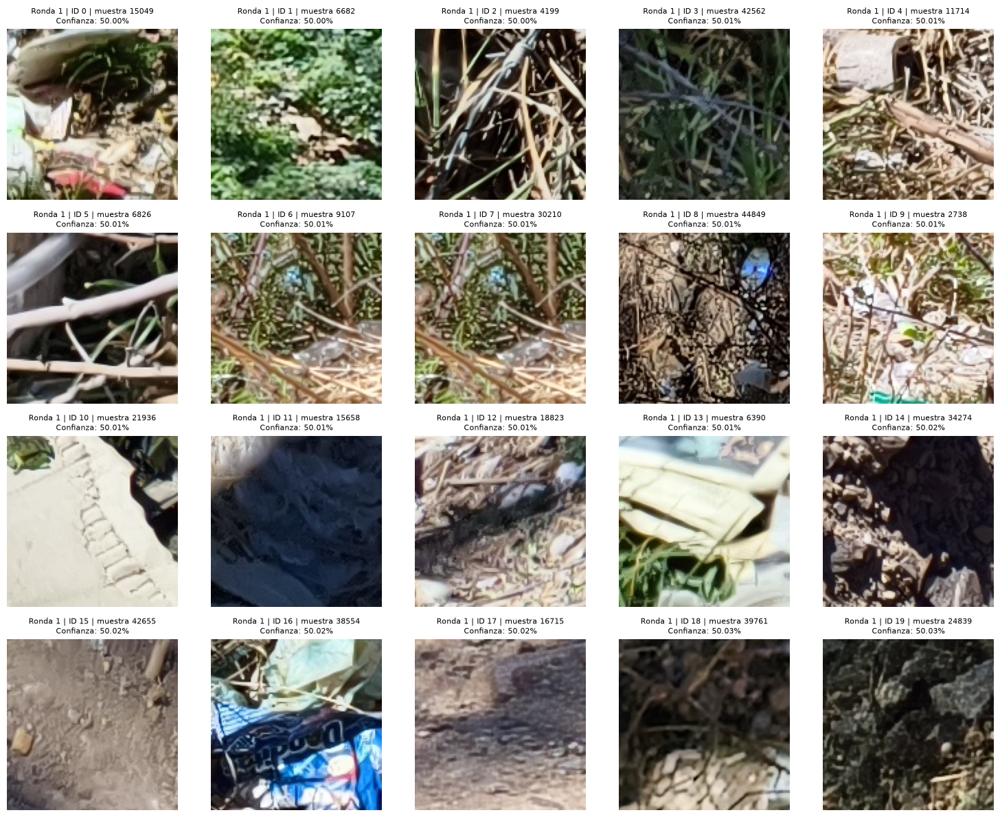

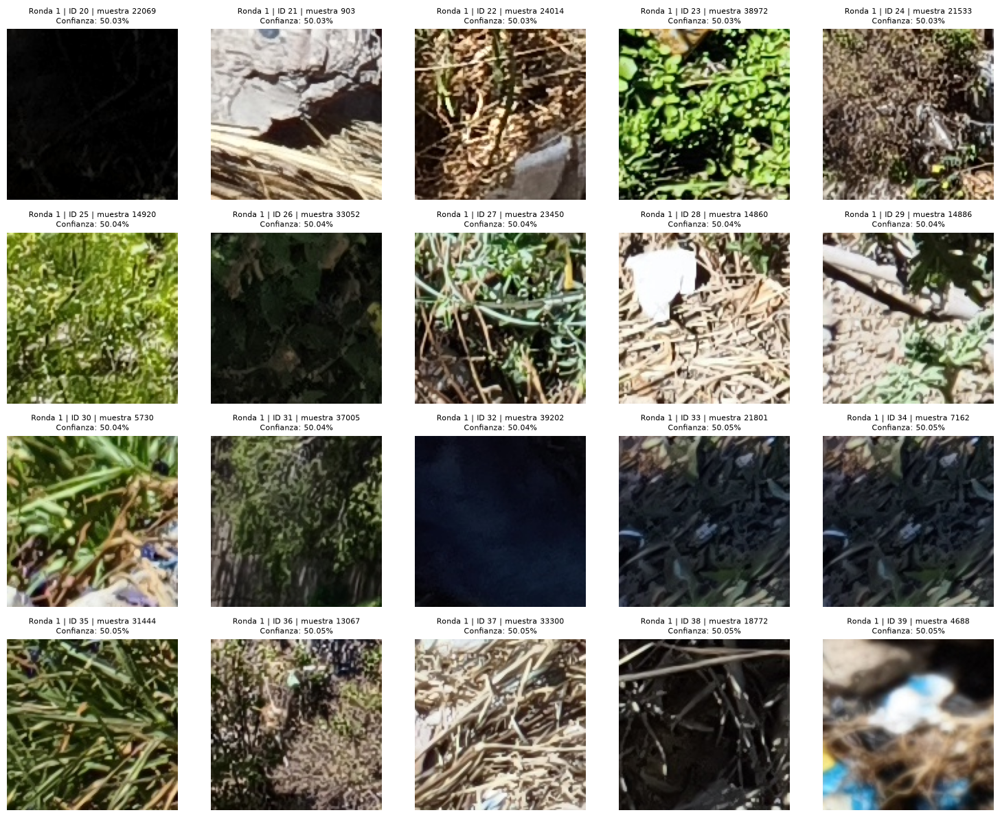

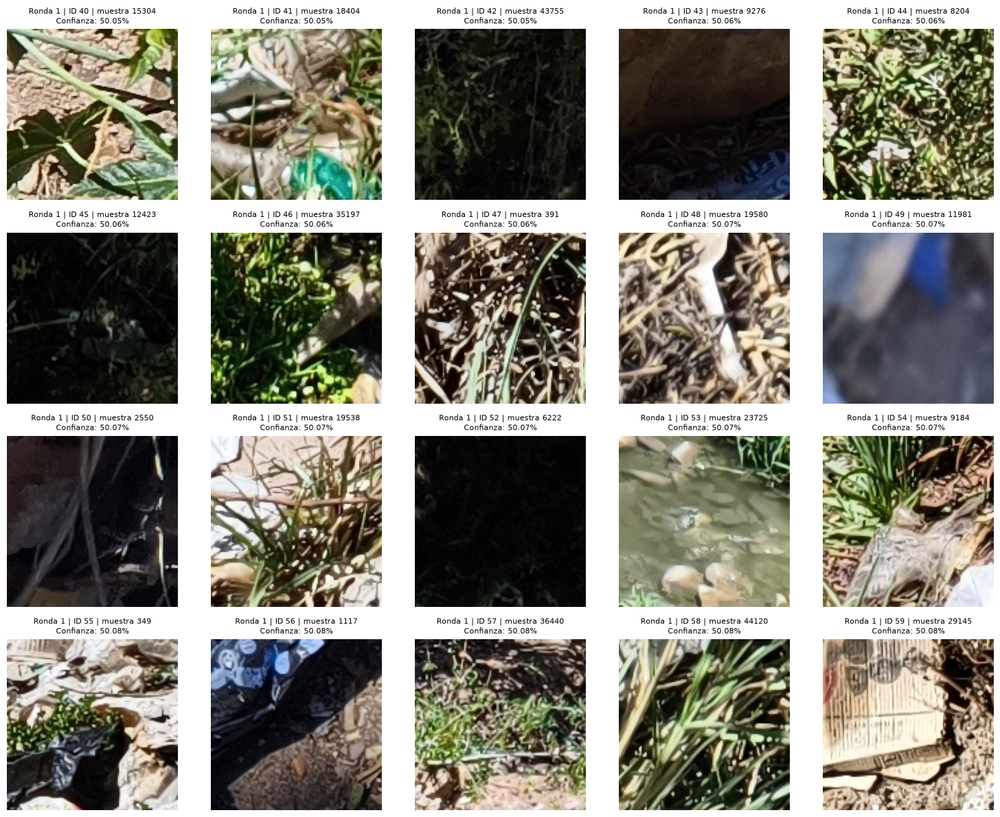

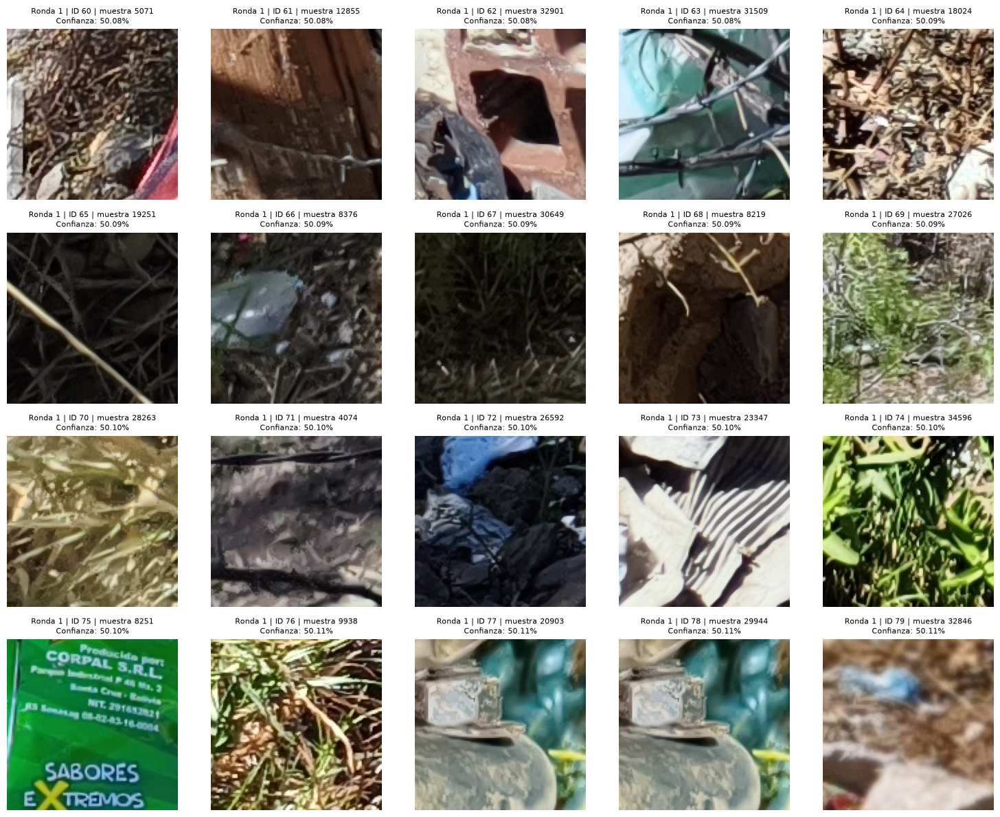

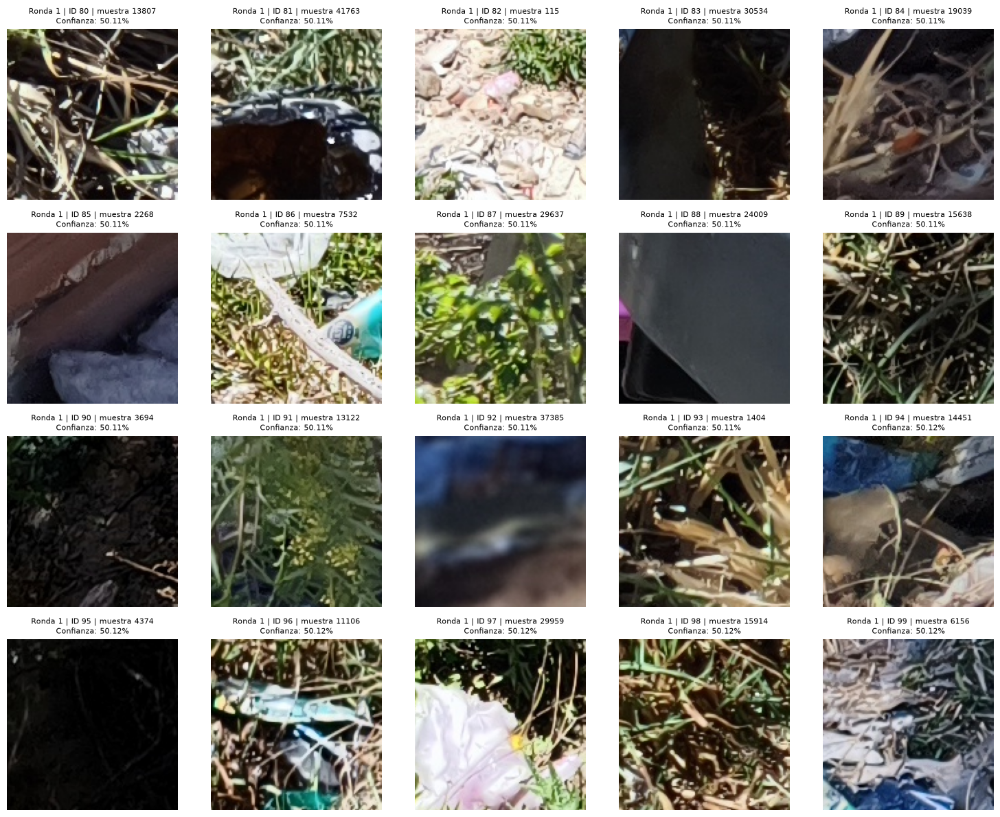

etiquetas_activo_1 = {
    0: -1,  # muestra 15049
    1: -1,  # muestra 6682
    2: -1,  # muestra 4199
    3: -1,  # muestra 42562
    4: -1,  # muestra 11714
    5: -1,  # muestra 6826
    6: -1,  # muestra 9107
    7: -1,  # muestra 30210
    8: -1,  # muestra 44849
    9: -1,  # muestra 2738
    10: -1,  # muestra 21936
    11: -1,  # muestra 15658
    12: -1,  # muestra 18823
    13: -1,  # muestra 6390
    14: -1,  # muestra 34274
    15: -1,  # muestra 42655
    16: -1,  # muestra 38554
    17: -1,  # muestra 16715
    18: -1,  # muestra 39761
    19: -1,  # muestra 24839
    20: -1,  # muestra 22069
    21: -1,  # muestra 903
    22: -1,  # muestra 24014
    23: -1,  # muestra 38972
    24: -1,  # muestra 21533
    25: -1,  # muestra 14920
    26: -1,  # muestra 33052
    27: -1,  # muestra 23450
    28: -1,  # muestra 14860
    29: -1,  # muestra 14886
    30: -1,  # muestra 5730
    31: -1,  # muestra 37005
    32: -1,  # muestra 39202
    33: -1,  # muestra 21801
    34: -1

In [33]:
mostrar_consultas_activas(seleccion_activo_1)


## 38. Ronda 1: editar y guardar sus 100 etiquetas




In [34]:
etiquetas_activo_1 = {
    0: 1,
    1: 0,
    2: 0,
    3: 0,
    4: 1,
    5: 0,
    6: 1,
    7: 1,
    8: 1,
    9: 1,
    10: 1,
    11: 0,
    12: 1,
    13: 1,
    14: 0,
    15: 0,
    16: 1,
    17: 0,
    18: 0,
    19: 0,
    20: 0,
    21: 0,
    22: 1,
    23: 0,
    24: 1,
    25: 0,
    26: 0,
    27: 0,
    28: 1,
    29: 0,
    30: 1,
    31: 0,
    32: 0,
    33: 1,
    34: 1,
    35: 0,
    36: 1,
    37: 0,
    38: 0,
    39: 1,
    40: 0,
    41: 1,
    42: 0,
    43: 1,
    44: 0,
    45: 0,
    46: 1,
    47: 0,
    48: 1,
    49: 1,
    50: 0,
    51: 1,
    52: 0,
    53: 1,
    54: 1,
    55: 1,
    56: 1,
    57: 0,
    58: 0,
    59: 1,
    60: 1,
    61: 0,
    62: 1,
    63: 1,
    64: 1,
    65: 0,
    66: 1,
    67: 0,
    68: 0,
    69: 0,
    70: 0,
    71: 0,
    72: 1,
    73: 1,
    74: 0,
    75: 1,
    76: 0,
    77: 1,
    78: 1,
    79: 1,
    80: 1,
    81: 1,
    82: 1,
    83: 0,
    84: 1,
    85: 0,
    86: 1,
    87: 0,
    88: 1,
    89: 0,
    90: 0,
    91: 0,
    92: 1,
    93: 0,
    94: 1,
    95: 0,
    96: 1,
    97: 1,
    98: 0,
    99: 1,
}
etiquetas_activo_1 = guardar_etiquetas_activas(1, etiquetas_activo_1)


Consultas limpias: 49
Consultas con basura: 51
Las 100 etiquetas estan completas.
Pseudoetiquetas incorrectas encontradas en esta consulta: 48
etiquetas_activo_1 = {
    0: 1,  # muestra 15049
    1: 0,  # muestra 6682
    2: 0,  # muestra 4199
    3: 0,  # muestra 42562
    4: 1,  # muestra 11714
    5: 0,  # muestra 6826
    6: 1,  # muestra 9107
    7: 1,  # muestra 30210
    8: 1,  # muestra 44849
    9: 1,  # muestra 2738
    10: 1,  # muestra 21936
    11: 0,  # muestra 15658
    12: 1,  # muestra 18823
    13: 1,  # muestra 6390
    14: 0,  # muestra 34274
    15: 0,  # muestra 42655
    16: 1,  # muestra 38554
    17: 0,  # muestra 16715
    18: 0,  # muestra 39761
    19: 0,  # muestra 24839
    20: 0,  # muestra 22069
    21: 0,  # muestra 903
    22: 1,  # muestra 24014
    23: 0,  # muestra 38972
    24: 1,  # muestra 21533
    25: 0,  # muestra 14920
    26: 0,  # muestra 33052
    27: 0,  # muestra 23450
    28: 1,  # muestra 14860
    29: 0,  # muestra 14886
    30: 1,  

## 39. Ronda 1: entrenar y guardar el primer modelo




In [35]:
seleccion_activo_1, correcciones_ronda_1 = recuperar_correcciones_activas(1, correcciones_iniciales_activo)
etiquetas_entrenamiento_1 = preparar_etiquetas_entrenamiento_activo(1, correcciones_ronda_1)
modelo_activo_1, historial_activo_1, segundos_activo_1 = entrenar_logistica_cuda(
    archivos_train_clf, etiquetas_entrenamiento_1,
    "activo_ronda_01", "logistica_activo_ronda_01.pt"
)
print("Ronda 1 guardada. Continua con las imagenes de la ronda 2 en la seccion 40.")


Etiquetas humanas acumuladas: 150
Etiquetas propagadas sustituidas: 48
Cargando 45000 imagenes para activo_ronda_01...
Cargadas 5120/45000
Cargadas 10240/45000
Cargadas 15360/45000
Cargadas 20480/45000
Cargadas 25600/45000
Cargadas 30720/45000
Cargadas 35840/45000
Cargadas 40960/45000
Cargadas 45000/45000
Carga y transferencia: 72.1 segundos.
activo_ronda_01: iteracion 1/2500 | costo del lote=0.69315
activo_ronda_01: iteracion 250/2500 | costo del lote=0.64143
activo_ronda_01: iteracion 500/2500 | costo del lote=0.62045
activo_ronda_01: iteracion 750/2500 | costo del lote=0.63395
activo_ronda_01: iteracion 1000/2500 | costo del lote=0.60648
activo_ronda_01: iteracion 1250/2500 | costo del lote=0.59453
activo_ronda_01: iteracion 1500/2500 | costo del lote=0.62812
activo_ronda_01: iteracion 1750/2500 | costo del lote=0.59936
activo_ronda_01: iteracion 2000/2500 | costo del lote=0.61317
activo_ronda_01: iteracion 2250/2500 | costo del lote=0.61619
activo_ronda_01: iteracion 2500/2500 | co

## 40. Ronda 2: seleccionar y mostrar otras 100 imágenes




In [36]:
seleccion_activo_1, correcciones_ronda_1 = recuperar_correcciones_activas(1, correcciones_iniciales_activo)
seleccion_activo_2 = seleccionar_consultas_activas(2, correcciones_ronda_1)


Cargando 45000 imagenes para seleccion activa...
Cargadas 5120/45000
Cargadas 10240/45000
Cargadas 15360/45000
Cargadas 20480/45000
Cargadas 25600/45000
Cargadas 30720/45000
Cargadas 35840/45000
Cargadas 40960/45000
Cargadas 45000/45000
Carga y transferencia: 48.8 segundos.
Modelo usado para seleccionar: activo_ronda_01
Imagenes disponibles sin etiqueta manual: 44850
Predicciones de basura en las 45.000: 2830
Confianza media en las 45.000: 67.75%
Confianza media de las 100 seleccionadas: 50.13%
Estas cantidades son predicciones del modelo, no conteos de basura real.


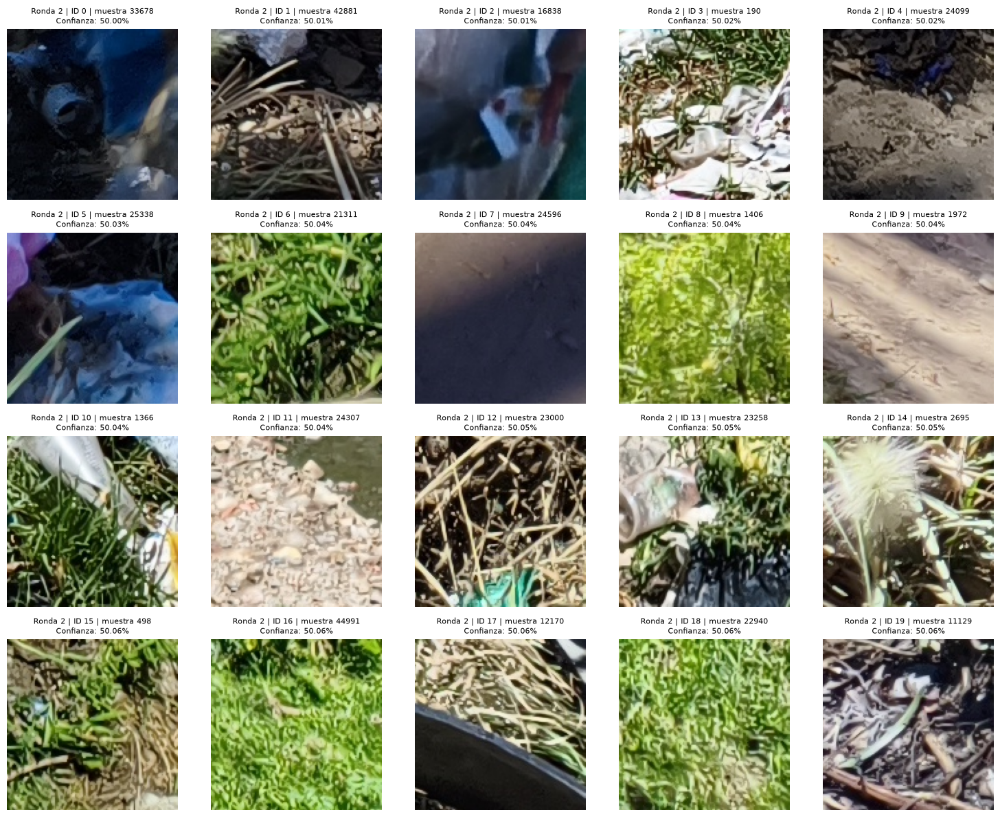

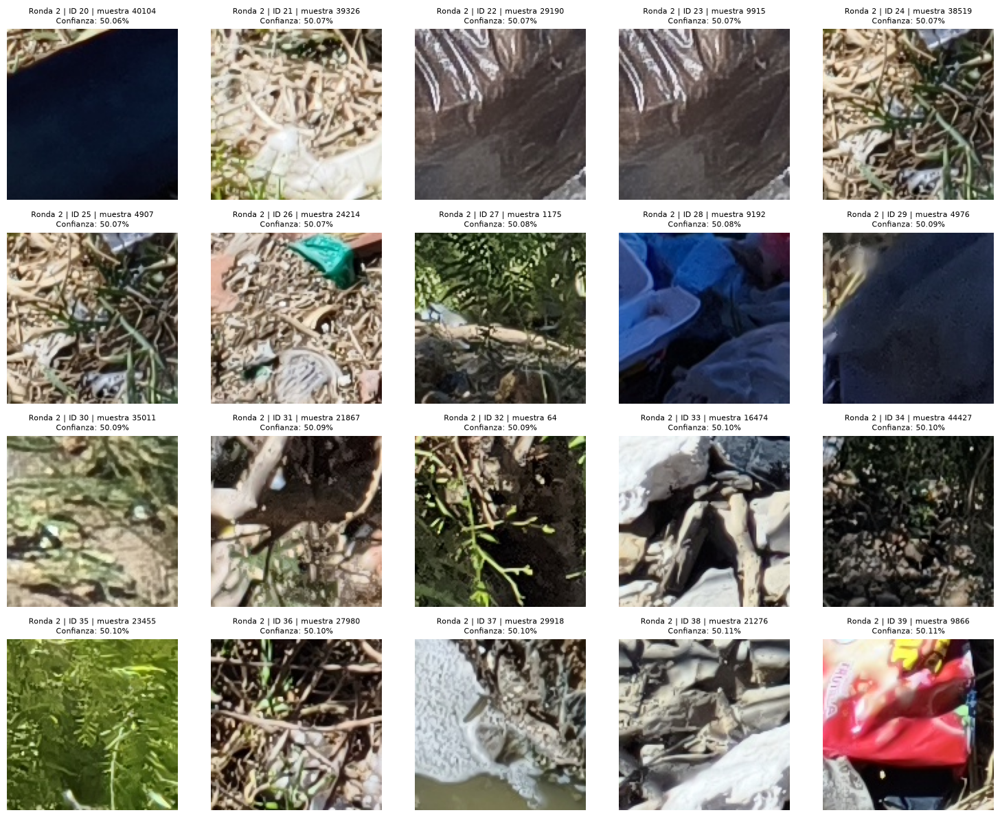

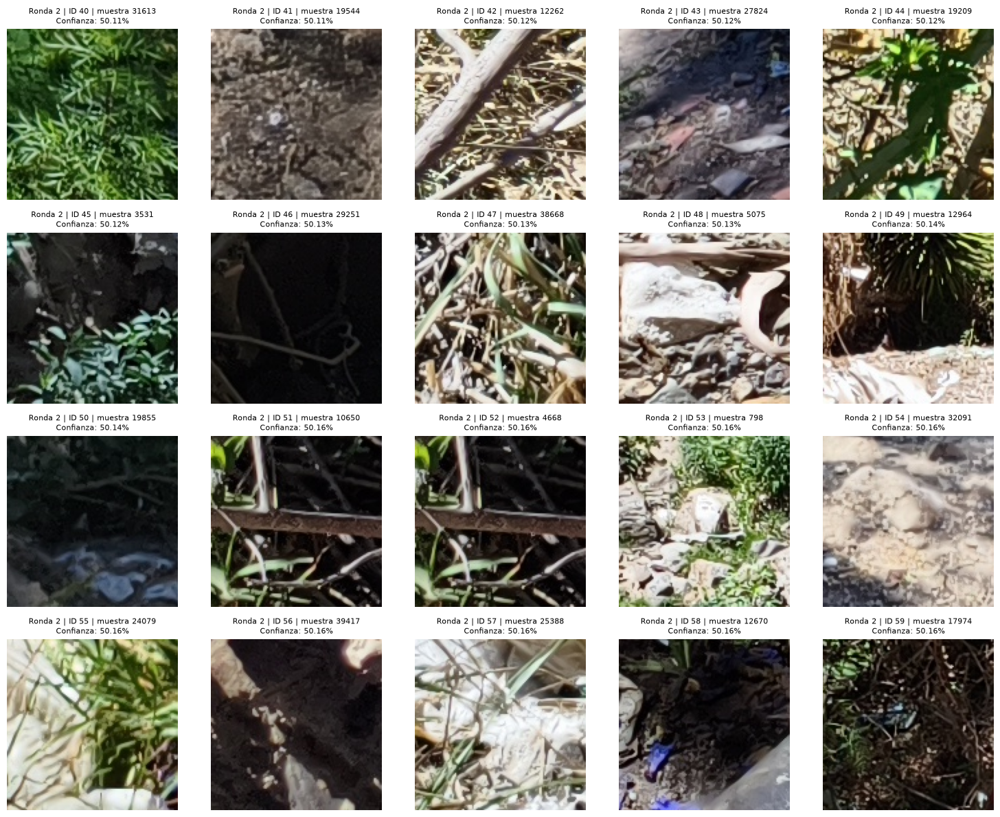

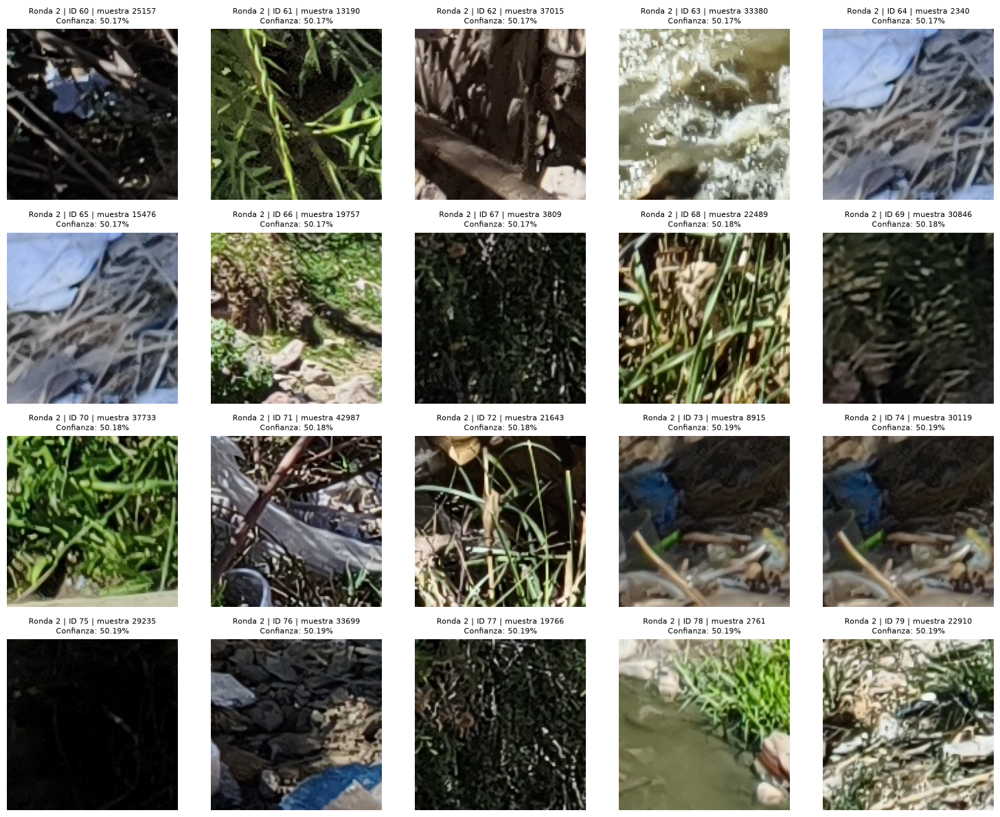

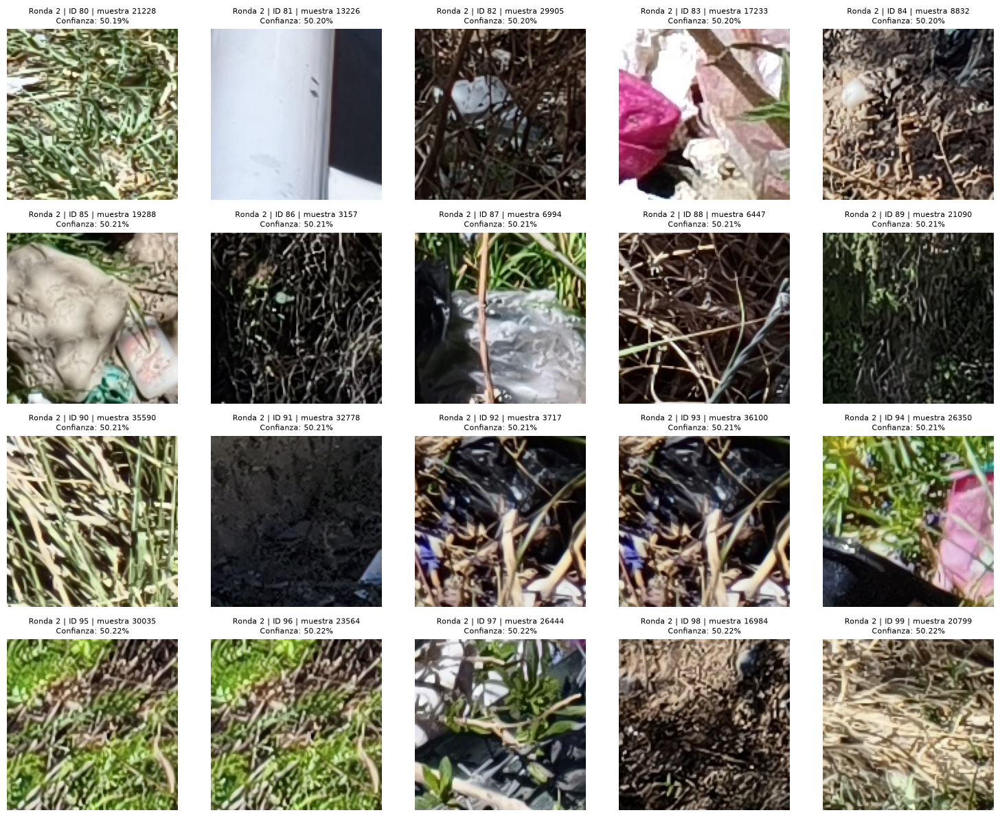

etiquetas_activo_2 = {
    0: -1,  # muestra 33678
    1: -1,  # muestra 42881
    2: -1,  # muestra 16838
    3: -1,  # muestra 190
    4: -1,  # muestra 24099
    5: -1,  # muestra 25338
    6: -1,  # muestra 21311
    7: -1,  # muestra 24596
    8: -1,  # muestra 1406
    9: -1,  # muestra 1972
    10: -1,  # muestra 1366
    11: -1,  # muestra 24307
    12: -1,  # muestra 23000
    13: -1,  # muestra 23258
    14: -1,  # muestra 2695
    15: -1,  # muestra 498
    16: -1,  # muestra 44991
    17: -1,  # muestra 12170
    18: -1,  # muestra 22940
    19: -1,  # muestra 11129
    20: -1,  # muestra 40104
    21: -1,  # muestra 39326
    22: -1,  # muestra 29190
    23: -1,  # muestra 9915
    24: -1,  # muestra 38519
    25: -1,  # muestra 4907
    26: -1,  # muestra 24214
    27: -1,  # muestra 1175
    28: -1,  # muestra 9192
    29: -1,  # muestra 4976
    30: -1,  # muestra 35011
    31: -1,  # muestra 21867
    32: -1,  # muestra 64
    33: -1,  # muestra 16474
    34: -1,  # mu

In [37]:
mostrar_consultas_activas(seleccion_activo_2)


## 41. Ronda 2: editar y guardar sus 100 etiquetas



In [38]:
etiquetas_activo_2 = {
    0: 1,
    1: 0,
    2: 1,
    3: 1,
    4: 0,
    5: 1,
    6: 0,
    7: 0,
    8: 0,
    9: 0,
    10: 1,
    11: 0,
    12: 1,
    13: 1,
    14: 0,
    15: 1,
    16: 0,
    17: 1,
    18: 0,
    19: 0,
    20: 0,
    21: 1,
    22: 1,
    23: 1,
    24: 1,
    25: 1,
    26: 1,
    27: 1,
    28: 1,
    29: 1,
    30: 1,
    31: 1,
    32: 0,
    33: 1,
    34: 0,
    35: 0,
    36: 0,
    37: 0,
    38: 1,
    39: 1,
    40: 0,
    41: 0,
    42: 0,
    43: 1,
    44: 0,
    45: 0,
    46: 0,
    47: 0,
    48: 1,
    49: 1,
    50: 1,
    51: 0,
    52: 0,
    53: 1,
    54: 0,
    55: 1,
    56: 0,
    57: 1,
    58: 1,
    59: 1,
    60: 1,
    61: 0,
    62: 0,
    63: 0,
    64: 1,
    65: 1,
    66: 0,
    67: 0,
    68: 0,
    69: 0,
    70: 0,
    71: 1,
    72: 0,
    73: 1,
    74: 1,
    75: 0,
    76: 1,
    77: 0,
    78: 0,
    79: 1,
    80: 0,
    81: 1,
    82: 1,
    83: 1,
    84: 0,
    85: 1,
    86: 0,
    87: 1,
    88: 0,
    89: 0,
    90: 0,
    91: 0,
    92: 1,
    93: 1,
    94: 1,
    95: 0,
    96: 0,
    97: 1,
    98: 0,
    99: 0,
}

etiquetas_activo_2 = guardar_etiquetas_activas(2, etiquetas_activo_2)


Consultas limpias: 51
Consultas con basura: 49
Las 100 etiquetas estan completas.
Pseudoetiquetas incorrectas encontradas en esta consulta: 45
etiquetas_activo_2 = {
    0: 1,  # muestra 33678
    1: 0,  # muestra 42881
    2: 1,  # muestra 16838
    3: 1,  # muestra 190
    4: 0,  # muestra 24099
    5: 1,  # muestra 25338
    6: 0,  # muestra 21311
    7: 0,  # muestra 24596
    8: 0,  # muestra 1406
    9: 0,  # muestra 1972
    10: 1,  # muestra 1366
    11: 0,  # muestra 24307
    12: 1,  # muestra 23000
    13: 1,  # muestra 23258
    14: 0,  # muestra 2695
    15: 1,  # muestra 498
    16: 0,  # muestra 44991
    17: 1,  # muestra 12170
    18: 0,  # muestra 22940
    19: 0,  # muestra 11129
    20: 0,  # muestra 40104
    21: 1,  # muestra 39326
    22: 1,  # muestra 29190
    23: 1,  # muestra 9915
    24: 1,  # muestra 38519
    25: 1,  # muestra 4907
    26: 1,  # muestra 24214
    27: 1,  # muestra 1175
    28: 1,  # muestra 9192
    29: 1,  # muestra 4976
    30: 1,  # mue

## 42. Ronda 2: entrenar y guardar el segundo modelo




In [39]:
seleccion_activo_1, correcciones_ronda_1 = recuperar_correcciones_activas(1, correcciones_iniciales_activo)
seleccion_activo_2, correcciones_ronda_2 = recuperar_correcciones_activas(2, correcciones_ronda_1)
etiquetas_entrenamiento_2 = preparar_etiquetas_entrenamiento_activo(2, correcciones_ronda_2)
modelo_activo_2, historial_activo_2, segundos_activo_2 = entrenar_logistica_cuda(
    archivos_train_clf, etiquetas_entrenamiento_2,
    "activo_ronda_02", "logistica_activo_ronda_02.pt"
)
print("Ronda 2 guardada. Ya puedes evaluar ambos modelos en la seccion 43.")


Etiquetas humanas acumuladas: 250
Etiquetas propagadas sustituidas: 93
Cargando 45000 imagenes para activo_ronda_02...
Cargadas 5120/45000
Cargadas 10240/45000
Cargadas 15360/45000
Cargadas 20480/45000
Cargadas 25600/45000
Cargadas 30720/45000
Cargadas 35840/45000
Cargadas 40960/45000
Cargadas 45000/45000
Carga y transferencia: 44.7 segundos.
activo_ronda_02: iteracion 1/2500 | costo del lote=0.69315
activo_ronda_02: iteracion 250/2500 | costo del lote=0.64043
activo_ronda_02: iteracion 500/2500 | costo del lote=0.62046
activo_ronda_02: iteracion 750/2500 | costo del lote=0.63295
activo_ronda_02: iteracion 1000/2500 | costo del lote=0.60651
activo_ronda_02: iteracion 1250/2500 | costo del lote=0.59450
activo_ronda_02: iteracion 1500/2500 | costo del lote=0.62825
activo_ronda_02: iteracion 1750/2500 | costo del lote=0.59923
activo_ronda_02: iteracion 2000/2500 | costo del lote=0.61303
activo_ronda_02: iteracion 2250/2500 | costo del lote=0.61645
activo_ronda_02: iteracion 2500/2500 | co

## 43. Evaluar los dos modelos guardados




Modelo recuperado del disco: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados clasificacion\logistica_activo_ronda_01.pt
Cargando 100 imagenes para testeo...
Cargadas 100/100
Carga y transferencia: 0.2 segundos.
activo_ronda_01: 64/100 aciertos | exactitud=64.00%
Basura: precision=33.33% | recall=5.88% | F1=10.00%
Imagenes con basura que el modelo marco como limpias: 32


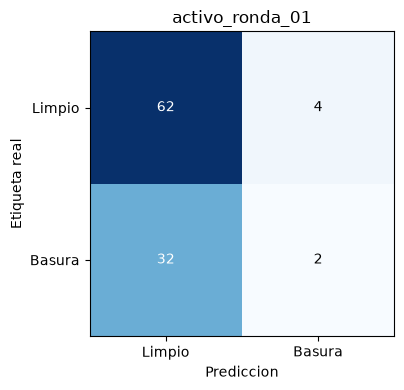

In [40]:
if not all(os.path.isfile(os.path.join(carpeta_salida_clf, nombre)) for nombre in
           ["logistica_activo_ronda_01.pt", "logistica_activo_ronda_02.pt"]):
    raise ValueError("Primero completa y guarda los entrenamientos de las secciones 39 y 42.")
modelo_evaluado_activo_1 = cargar_modelo_ronda_activa(1)
metricas_activo_1 = evaluar_logistica_cuda(modelo_evaluado_activo_1, "activo_ronda_01")


Modelo recuperado del disco: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados clasificacion\logistica_activo_ronda_02.pt
Cargando 100 imagenes para testeo...
Cargadas 100/100
Carga y transferencia: 0.2 segundos.
activo_ronda_02: 64/100 aciertos | exactitud=64.00%
Basura: precision=33.33% | recall=5.88% | F1=10.00%
Imagenes con basura que el modelo marco como limpias: 32


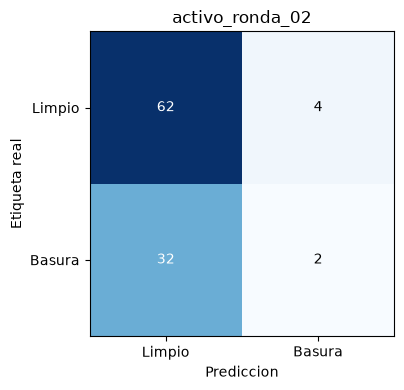

In [41]:
modelo_evaluado_activo_2 = cargar_modelo_ronda_activa(2)
metricas_activo_2 = evaluar_logistica_cuda(modelo_evaluado_activo_2, "activo_ronda_02")


## 44. Comparar los resultados guardados y la confianza



TESTEO FIJO | Exactitud | Precision basura | Recall basura | F1 basura | Confianza media
50_manuales | 56.00% | 35.29% | 35.29% | 35.29% | 68.39%
45000_propagadas | 64.00% | 33.33% | 5.88% | 10.00% | 67.28%
activo_ronda_01 | 64.00% | 33.33% | 5.88% | 10.00% | 67.23%
activo_ronda_02 | 64.00% | 33.33% | 5.88% | 10.00% | 67.20%

Etapa | Basura detectada / real | Probabilidad media de basura en basura real
50_manuales | 12 / 34 | 40.69%
45000_propagadas | 2 / 34 | 30.81%
activo_ronda_01 | 2 / 34 | 30.86%
activo_ronda_02 | 2 / 34 | 30.92%
Referencia: siempre limpio = 66.00% de exactitud, 0% de recall de basura.


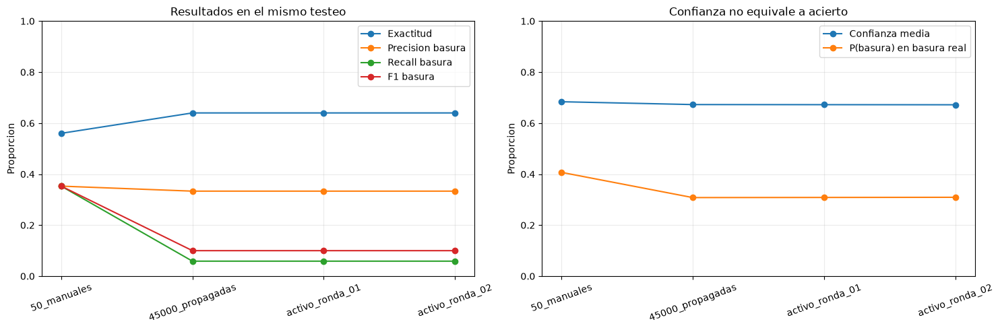

In [42]:
etapas_comparacion_activo = ["50_manuales", "45000_propagadas", "activo_ronda_01", "activo_ronda_02"]
comparacion_testeo_activo = []
for etapa in etapas_comparacion_activo:
    with open(os.path.join(carpeta_salida_clf, f"metricas_{etapa}.json"), encoding="utf-8") as archivo:
        metricas = json.load(archivo)
    if metricas["huella_testeo"] != huella_test_clf or metricas["umbral"] != umbral_clf:
        raise ValueError("No se pueden comparar evaluaciones con otro testeo o umbral.")
    with open(os.path.join(carpeta_salida_clf, f"predicciones_{etapa}.csv"), newline="", encoding="utf-8") as archivo:
        filas = list(csv.DictReader(archivo))
    if (len(filas) != len(muestra_test_clf)
            or [int(fila["indice_test"]) for fila in filas] != list(range(len(muestra_test_clf)))
            or [fila["archivo"] for fila in filas] != muestra_test_clf
            or [int(fila["etiqueta_real"]) for fila in filas] != etiquetas_test_clf.tolist()):
        raise ValueError("Las predicciones guardadas no corresponden al mismo testeo manual.")
    probabilidades_test = np.array([float(fila["probabilidad_basura"]) for fila in filas])
    resumen = resumen_confianza_activo(probabilidades_test, etiquetas_test_clf)
    if not np.isclose(resumen["exactitud"], metricas["exactitud"]):
        raise ValueError("Revisa las metricas y predicciones guardadas de esta etapa.")
    fila_comparacion = {
        "etapa": etapa, "exactitud": metricas["exactitud"],
        "precision_basura": metricas["precision_basura"], "recall_basura": metricas["recall_basura"],
        "f1_basura": metricas["f1_basura"], "basura_correcta": metricas["basura_correcta"],
        "basura_no_detectada": metricas["basura_no_detectada"],
    }
    fila_comparacion.update(resumen)
    comparacion_testeo_activo.append(fila_comparacion)

with open(os.path.join(carpeta_activo, "comparacion_testeo.csv"), "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(comparacion_testeo_activo[0]))
    escritor.writeheader()
    escritor.writerows(comparacion_testeo_activo)
print("TESTEO FIJO | Exactitud | Precision basura | Recall basura | F1 basura | Confianza media")
for fila in comparacion_testeo_activo:
    print(f"{fila['etapa']} | {fila['exactitud']:.2%} | {fila['precision_basura']:.2%} | {fila['recall_basura']:.2%} | {fila['f1_basura']:.2%} | {fila['confianza_media']:.2%}")
print("\nEtapa | Basura detectada / real | Probabilidad media de basura en basura real")
for fila in comparacion_testeo_activo:
    print(f"{fila['etapa']} | {fila['basura_correcta']} / {fila['basura_real']} | {fila['probabilidad_basura_media_en_basura_real']:.2%}")
print(f"Referencia: siempre limpio = {np.mean(etiquetas_test_clf == 0):.2%} de exactitud, 0% de recall de basura.")

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
posiciones = np.arange(len(comparacion_testeo_activo))
for metrica, titulo in [("exactitud", "Exactitud"), ("precision_basura", "Precision basura"),
                        ("recall_basura", "Recall basura"), ("f1_basura", "F1 basura")]:
    ejes[0].plot(posiciones, [fila[metrica] for fila in comparacion_testeo_activo], marker="o", label=titulo)
for metrica, titulo in [("confianza_media", "Confianza media"),
                        ("probabilidad_basura_media_en_basura_real", "P(basura) en basura real")]:
    ejes[1].plot(posiciones, [fila[metrica] for fila in comparacion_testeo_activo], marker="o", label=titulo)
for eje, titulo in zip(ejes, ["Resultados en el mismo testeo", "Confianza no equivale a acierto"]):
    eje.set_xticks(posiciones, etapas_comparacion_activo, rotation=20)
    eje.set(title=titulo, ylim=(0, 1), ylabel="Proporcion")
    eje.grid(alpha=0.25)
    eje.legend()
plt.tight_layout()
fig.savefig(os.path.join(carpeta_activo, "comparacion_testeo.png"), dpi=150)
plt.show()
plt.close(fig)


In [43]:
modelos_seguimiento_activo = {
    "activo_ronda_01": cargar_modelo_ronda_activa(1),
    "activo_ronda_02": cargar_modelo_ronda_activa(2),
}
comparacion_consultas_activo = []
for numero_lote in (1, 2):
    seleccion_lote = leer_seleccion_activa(numero_lote)
    carpeta_lote = os.path.join(carpeta_activo, f"ronda_{numero_lote:02d}")
    etiquetas_lote = leer_etiquetas_activas(os.path.join(carpeta_lote, "etiquetas.json"), seleccion_lote, True)
    reales_lote = np.array([etiquetas_lote[i] for i in range(consultas_por_ronda)], dtype=np.int64)
    resumen_antes = resumen_confianza_activo(np.array(seleccion_lote["probabilidades_basura_antes"]), reales_lote)
    comparacion_consultas_activo.append({"lote": numero_lote, "etapa": seleccion_lote["etapa_origen"], **resumen_antes})
    etapas_lote = ["activo_ronda_01", "activo_ronda_02"] if numero_lote == 1 else ["activo_ronda_02"]
    rutas_lote = [archivos_train_clf[i] for i in seleccion_lote["indices_train"]]
    for etapa in etapas_lote:
        probabilidades = probabilidades_cuda_activo(modelos_seguimiento_activo[etapa], rutas_lote, f"lote {numero_lote} - {etapa}")
        resumen = resumen_confianza_activo(probabilidades, reales_lote)
        comparacion_consultas_activo.append({"lote": numero_lote, "etapa": etapa, **resumen})

with open(os.path.join(carpeta_activo, "seguimiento_lotes.csv"), "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(comparacion_consultas_activo[0]))
    escritor.writeheader()
    escritor.writerows(comparacion_consultas_activo)
print("CONSULTAS DE ENTRENAMIENTO | Confianza media | Aciertos en lote | Basura real | Predice basura")
for fila in comparacion_consultas_activo:
    print(f"Lote {fila['lote']} - {fila['etapa']} | {fila['confianza_media']:.2%} | {fila['exactitud']:.2%} | {fila['basura_real']} / 100 | {fila['predicciones_basura']} / 100")
print("Estos aciertos son sobre imagenes de entrenamiento; revisa el testeo para evaluar la mejora.")
print("Resultados guardados en:", carpeta_activo)


Modelo recuperado del disco: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados clasificacion\logistica_activo_ronda_01.pt
Modelo recuperado del disco: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados clasificacion\logistica_activo_ronda_02.pt
Cargando 100 imagenes para lote 1 - activo_ronda_01...
Cargadas 100/100
Carga y transferencia: 0.1 segundos.
Cargando 100 imagenes para lote 1 - activo_ronda_02...
Cargadas 100/100
Carga y transferencia: 0.1 segundos.
Cargando 100 imagenes para lote 2 - activo_ronda_02...
Cargadas 100/100
Carga y transferencia: 0.1 segundos.
CONSULTAS DE ENTRENAMIENTO | Confianza media | Aciertos en lote | Basura real | Predice basura
Lote 1 - 45000_propagadas | 50.07% | 50.00% | 51 / 100 | 55 / 100
Lote 1 - activo_ronda_01 | 50.20% | 73.00% | 51 / 100 | 64 / 100
Lote 1 - activo_ronda_02 | 50.25% | 74.00% | 51 / 100 | 65 / 100
Lote 2 - activo_ronda_01 | 50.13% | 52.00% | 49 / 100 | 33 / 100